# 2-motor: compensation

Find out how accurate a back-EMF speed estimate built from the board's own signals is, with the reading term $\Delta$ and the brush drop $V_b$ compensated, first with stage 2's reference constants and then with the constants identification recovered board-only. The gap between the two is the price of identifying without a meter.

## Purpose

A servo's board knows the duty it applied, the terminal volts over the PWM window, the crest current sample and its rail. The motor's equation turns them into a speed,

$$\hat\omega = \frac{V_\mathrm{mean} - R\,\big(i_\mathrm{crest} - \Delta(D)\,V_\mathrm{window}\big) - V_b(\hat\omega, \mathrm{dir}, \dot n_d)}{K_e}$$

with $\hat\omega$ the estimate ("omega hat"), $V_\mathrm{mean}$ the terminal volts' mean over the period, $R$ the terminal resistance, $i_\mathrm{crest}$ the current sampled once a period at the crest, $K_e$ the back-EMF constant, $D$ the applied duty and $\dot n_d$ the dropout rate, the periods a second whose crest sample sits near zero. $V_\mathrm{mean}$ is the share construction from motor-model, the window's volts times the share of the period the bridge drives, less the brake loop's drop over the rest of the period.

Two terms correct what the board reads. motor-model found that the crest sample sits above the period's mean current by a reading term, about 20 to 30 mA on the spinning motor, falling to zero at 100 % where nothing switches. Here it is a table $f(D)$ in mA per volt of the window, so $\Delta = f(D)\,V_\mathrm{window}$. motor-model also found a voltage on the turning motor beyond the EMF and the copper's drop, which it called the brush drop: set by the speed and the direction of rotation and not by the current, a few millivolts under 160 rev/s and a few hundred at 550 rev/s. identification reads it in two parts, a coefficient $k_d$ times the dropout rate, which the board counts from the same crest samples, and a table of the speed per mechanical direction; the speed-only table and a power law are kept beside it. The dropout part does not depend on $\hat\omega$ and comes off before the solve. The speed part does, and since the EMF and the speed part together rise with speed the equation has one root, found by bisection.

The speed truth is the ripple tach, the commutation ripple counted at six events per revolution in the same samples. It never enters the estimator.

The two corrections pull in opposite directions, so they have to come together or not at all. Without $\Delta$ the crest current is too large, $R\,i$ is too large, and the speed reads low by a nearly fixed 12 to 16 rev/s, which at 15 % duty is 17 to 21 % of the speed. Without $V_b$ the drop is counted as EMF and the speed reads high, by an amount that grows with about the fourth power of the speed. Between about 250 and 350 rev/s the two errors cancel, and the uncompensated estimate looks good there by luck. Taking out only one of them leaves the other uncovered, so either alone can make the estimate worse than none. The headline shows each case.

## Procedure

This notebook has no capture of its own. It reads stage 2's spinning captures and scores each spin, or each one-turn window, against the ripple tach.

- capture-1 is scored by repeat. $V_b$, its $k_d$ and its tables, is fitted on two repeats and the third is scored, three folds. $\Delta$ comes from the grid at the $G$ fitted on the meter runs alone, so capture-1 is in neither fit that scores it.
- swapped-1, a day later, was never in any fit. It is scored on capture-1's $V_b$ and the published grid.
- speed-torque's run-ups at 100 % carry two to eleven times the free current and were never in a $V_b$ fit. They are scored on capture-1's $V_b$. $\Delta$ is zero at 100 %, so there "$\Delta$ only" is uncompensated and "both" is "$V_b$ only".

The meter runs are not speed-scored. Their voltage path carries the meter's 9.50 ohm loop, and that number was itself derived with $V_b$, so a speed score there would grade $V_b$ against itself.

Then the same estimator runs on the constants identification recovered, one pass at a time. A pass is one locked seat for $R$ and $L$, one repeat's 20 coasts for $K_e$, one run-up each way and that repeat's spins for $\Delta$ by the 100 % anchor, and six of those spins, 7.4 V at 30, 40 and 60 % both ways, for $V_b$. Twelve seats and three repeats make 36 passes.

## Data

Every folder is under `telemetry/mg90-b__dev-v006-2A-D/`.

- `bemf-coast/capture-1/`, ten rungs, 15 to 60 % at 5.0 and 7.4 V, three repeats both ways, each a 1.5 s spin and a coast with the bridge open.
- `bemf-coast/swapped-1/`, 7.4 V 40 and 60 % with the leads as wired and then swapped at the board's connector, the day after.
- `bemf-coast/meter-1/` and `high-1/`, the DMM in series, the day after, for $\Delta$ against the meter only.
- `speed-torque/capture-1/`, three 300 ms run-ups at 100 % on 5.0 V each way, through speed-torque's own turn-window cells.
- For the identified constants, `rest-resistance/capture-1/stall/` and `inductance/capture-1/` through those notebooks' own cells, as identification reads them.

### The results carried in

From stage 1, current-scale, terminal-chain, sample-timing, bridge-states and ntc-curve, through motor-model's and identification's modules. From stage 2, rest-resistance's locked $R$ and its thermal numbers, inductance's $L$, bemf-coast's $K_e$ with its bounds, speed-torque's inertia and turn windows, and motor-model's no-meter and meter reading-term grids, its $G$, its brush-drop fit, its coast scale and its meter loop. identification's result file is read to check that every pass constant rebuilt here is the one it graded.

The only numbers typed in are copper's resistance coefficient, 0.39 % per C, a physical constant, and the servo's geometry, the gear ratio of 308.05 from identification's tooth count, which only turns motor rev/s into degrees per second at the horn. The method has its own settings, chosen before any score was read. They are the 50 rev/s knots of the $V_b$ table, the 200 rev/s floor of the power law, the quarter of the window mean that counts a dropout, the 50 ms the dropout rate is read over at least, the tach gate's 0.3 % and 1 %, the 2 % move of $R$, and the 0.2 point rule for a $V_b$ subset.

## Method

### The two tables

**$f(D)$.** motor-model's published no-meter grid, divided by its rail and averaged over its four rails, interpolated in applied duty, flat below 10 % and zero at 100 %. For a held-out $G$, motor-model's steady states are rebuilt at $G$ = 0 and 2 mS, so every grid cell is a line in $G$ and the grid at any $G$ is the published grid moved along that line.

**$V_b$.** Per spin, $X = V_\mathrm{mean} - K_e\,\omega - R\,(i_\mathrm{crest} - \Delta)$, with $\omega$ the ripple tach, so $X$ is what is left of the terminal volts once the EMF and the copper's drop are out. The EMF is the estimator's own $K_e$ at the tach's speed and not the coast's $E_0$, so whatever $K_e$ does with speed lands in $X$ and the estimator inherits none of it. Three forms are scored. The power law $A\,(\omega/300)^n$ is a line in logs through the rung means of $X$ over 200 rev/s. The speed table has knots every 50 rev/s from 150 to 650, the rung means interpolated between, the last segment extended past the top rung, and at and below 150 rev/s the low rungs' mean when the two rails agree and zero when they split. The third form, the table with $k_d$, first fits one coefficient on the dropout rate over every spin, with one level per rung shared by both directions, and then builds the same table on the rung means of $X - k_d\,\dot n_d$. The dropout rate is the rows of the window whose crest sits under a quarter of its mean, per second, one fixed fraction every notebook and the board count by; on the run-up windows, one turn long, it is read over 50 ms around the window.

The mechanical direction is the board's direction times the leads' orientation, +1 for the rotor direction that opens more. capture-1 and speed-torque ran one way, meter-1, high-1 and swapped-1's wired block the other, swapped-1's swapped block the first way again. The section on the direction tests the mapping.

### The estimate

Per spin the board's signals are read over the last 200 ms before the cut, the applied duty from the half ticks, the crest terminal difference, the crest current with the zero and the in-drive offset off, the rail tap and the dropout rate. The four variants are the estimate with neither term, with $\Delta$ only, with $V_b$ only, and with both. Speed-torque's windows are one turn long, and their estimate is $\hat\omega = (u - L\,di/dt - R\,i - V_b(\hat\omega))/K_e$ with speed-torque's own $u$, $L$ and current slope.

The error is the estimate less the ripple tach, as a mean signed error and an rms, in % of the tach speed and in rev/s, by speed band.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import results
import compensation as cp                                                # this notebook's estimator and its scoring, beside it

idn, mm, bd = cp.idn, cp.mm, cp.bd                                       # identification's pieces, and motor-model's modules through it
BLUE, ORANGE, INK, MUTED, GREEN = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#1baf7a"   # the house colors
VAR_COLOR = {"none": MUTED, "delta": ORANGE, "vb": GREEN, "both": BLUE}  # one color per variant, fixed through the notebook
VAR_LABEL = {"none": "uncompensated", "delta": r"$\Delta$ only", "vb": r"$V_b$ only", "both": "both"}
MECH_COLOR = {1: BLUE, -1: ORANGE}                                      # one color per mechanical direction, as in identification
MARK = {1: "o", -1: "^"}
pd.set_option("display.width", 220)
print(cp.MOTOR.key, "on", cp.BOARD.key)
for run, p in bd.RUNS.items():
    print(f"  {run:13s} {results.rel(p)}")
print(f"  {'swapped-1':13s} {results.rel(idn.SWAP)}")
# every reference constant from its results file
print(f"R {cp.R_LOCKED:.4f} ohm, the locked 12-hole median (rest-resistance); Ke {cp.KE * 1e3:.5f} mV s/rad, "
      f"{cp.KE_LO * 1e3:.4f} to {cp.KE_HI * 1e3:.4f} (bemf-coast); brake loop {cp.R_BRK:.3f} ohm (bridge-states)")
print(f"G_spin {cp.G_SPIN * 1e3:.3f} mS, the meter's loop in the voltage path {cp.R_METER:.2f} ohm, the reading-term grid and the "
      f"published brush drop (motor-model)")
print(f"gear {cp.GEAR:.2f}:1 (identification's tooth count), so 1 motor rev/s is {360 / cp.GEAR:.3f} deg/s at the horn")
IDR = results.read("2-motor", "identification", pair=cp.MOTOR.key)      # the constants identification recovered board-only
print("identification's result carries: " + ", ".join(k for k in IDR if k not in ("capture", "notes")))

mg90-b on dev-v006-2A-D
  capture-1     telemetry/mg90-b__dev-v006-2A-D/bemf-coast/capture-1
  meter-1       telemetry/mg90-b__dev-v006-2A-D/bemf-coast/meter-1
  high-1        telemetry/mg90-b__dev-v006-2A-D/bemf-coast/high-1
  speed-torque  telemetry/mg90-b__dev-v006-2A-D/speed-torque/capture-1
  swapped-1     telemetry/mg90-b__dev-v006-2A-D/bemf-coast/swapped-1
R 4.4553 ohm, the locked 12-hole median (rest-resistance); Ke 1.16838 mV s/rad, 1.1605 to 1.1725 (bemf-coast); brake loop 0.301 ohm (bridge-states)
G_spin 3.349 mS, the meter's loop in the voltage path 9.50 ohm, the reading-term grid and the published brush drop (motor-model)
gear 308.05:1 (identification's tooth count), so 1 motor rev/s is 1.169 deg/s at the horn
identification's result carries: servo_travel_motor_revs, r_one_seat_ohm, r_two_seats_ohm, r_three_seats_ohm, r_board_ntc_move_pct, r_reference_rung, ke_v_s_per_rad, l_mh, l_ripple_mh, c_a_s_per_v, delta_f_ma_per_v, v_b_mv


The per-spin reduction is identification's, motor-model's brush-drop reduction widened to swapped-1, and beside it motor-model's coast reduction of every spinning point for the drag at each cut. The ripple tach counts as a truth where its two seeds agree to 0.3 % and, over 150 rev/s, where it sits within 1 % of the coast's own speed at the cut. That keeps all 60 of capture-1's spins and 9 of 12 in each swapped-1 block. The six dropped spins are all at 60 %, where the tach slipped by 0.5 to 7.7 % against the coast.

In [2]:
# identification's per-spin reduction of every spinning capture, and motor-model's coast reduction of the spinning points
RED = cp.reductions()
TB, SL, CT = RED["TB"], RED["SL"], RED["CT"]
for run, T in TB.items():
    print(f"{run:16s} {len(T):3d} spins in {T['folder'].nunique():2d} folders")
C1 = cp.tag_mech(TB["capture-1"], "capture-1")                          # capture-1 with its mechanical direction
ok, _ = cp.tach_gate(C1)
print(idn.kept("capture-1 spins", C1[ok], ["repeat"]))
SW, DROP = {}, {}
for block in ("wired", "swapped"):
    run = f"swapped-{block}"
    T = cp.tag_mech(TB[run], run)
    okw, DROP[block] = cp.tach_gate(T)                                  # the spins where the tach slipped come out
    SW[block] = T[okw.to_numpy()].copy()
    print(idn.kept(f"swapped-1 {block}, gated", SW[block], ["duty", "dir"]))
    print(DROP[block][["duty", "dir", "spin_rev_s", "spin_rev_s_rough", "rev_s_cut_win", "seed_diff_pct", "tach_less_coast_pct"]].round(2).to_string())
WIN = cp.windows()                                                       # speed-torque's turn windows, its own cells
RU, RS, L_H = WIN["RU"], WIN["RS"], WIN["L_H"]
print(f"speed-torque windows: {len(WIN['REV'])} kept by its estimator, run-up {len(RU)} at {RU['rev_s'].min():.0f} to {RU['rev_s'].max():.0f} rev/s "
      f"and {RU['i'].min() * 1e3:.0f} to {RU['i'].max() * 1e3:.0f} mA, settled {len(RS)}; L {L_H * 1e3:.4f} mH")

capture-1         60 spins in 30 folders
speed-torque       6 spins in  3 folders
meter-1           18 spins in  9 folders
high-1            18 spins in  9 folders
swapped-wired     12 spins in  6 folders
swapped-swapped   12 spins in  6 folders
[capture-1 spins] kept 60 rows: 0:20, 1:20, 2:20
[swapped-1 wired, gated] kept 9 rows: (40, -1):3, (40, 1):3, (60, -1):3
    duty  dir  spin_rev_s  spin_rev_s_rough  rev_s_cut_win  seed_diff_pct  tach_less_coast_pct
6     60    1      503.01            505.59         505.60           0.51                -0.51
8     60    1      476.90            467.60         496.56           1.95                -3.96
10    60    1      462.03            443.30         500.73           4.06                -7.73
[swapped-1 swapped, gated] kept 9 rows: (40, -1):3, (40, 1):3, (60, 1):3
    duty  dir  spin_rev_s  spin_rev_s_rough  rev_s_cut_win  seed_diff_pct  tach_less_coast_pct
7     60   -1      492.64            502.66         500.34           2.03            

speed-torque windows: 5397 kept by its estimator, run-up 1514 at 188 to 577 rev/s and 119 to 727 mA, settled 3883; L 0.8333 mH


### The reading term at a held-out G

motor-model fitted its spinning loss $G$ to 18 points, capture-1's ten rungs and eight meter points. To score capture-1 without it in $\Delta$, $G$ is refitted on the meter runs alone and the grid is moved to that $G$.

In [3]:
# motor-model's 18 spinning points and its crest-term grid rebuilt at G = 0 and 2 mS, so each is a line in G; G refitted
# on capture-1 alone and on the meter runs alone (216 steady states on every core)
DG = cp.delta_grid(CT)
GR, GF, PTS = DG["GR"], DG["GF"], DG["PTS"]
print(f"{DG['n_jobs']} steady states; the drag curve {DG['CD'][0]:.1f} + {DG['CD'][1]:.3f} sqrt(w) mA; coast scale {DG['c_scale']:.4f}, "
      f"the pairing meter R {DG['R_M']:.2f} ohm")
for k, (g, se, chi2) in GF.items():
    print(f"  G fitted on {k:16s}: {g * 1e3:.3f} +/- {se * 1e3:.3f} mS, chi2/dof {chi2:.2f}")
print(f"  published G_spin {cp.G_SPIN * 1e3:.3f} mS")
print(f"the line at G_spin less the published grid: max |.| {GR[GR['loop'] == 'no meter']['lin_less_pub'].abs().max():.3f} mA (no meter), "
      f"{GR[GR['loop'] == 'meter']['lin_less_pub'].abs().max():.3f} mA (meter); the line against a direct run at G_spin {np.abs(DG['lin_err']).max():.3f} mA")
FT_PUB = cp.f_table(GR)                                                 # f(D) of the published grid, the rail mean per volt
assert np.allclose(FT_PUB[1], idn.f_table_published()[1])               # the same table identification reads
G_HELD = GF["meter runs only"][0]                                       # G with capture-1 left out
FT_HELD = cp.f_table(GR, G_HELD - cp.G_SPIN)                            # the grid moved along its line to that G
print("f(D), mA/V, published G:       " + ", ".join(f"{d:g} {v:.3f}" for d, v in zip(*FT_PUB) if 0 < d < 100))
print("f(D), mA/V, G from meter runs: " + ", ".join(f"{d:g} {v:.3f}" for d, v in zip(*FT_HELD) if 0 < d < 100))

216 steady states; the drag curve 20.4 + 1.353 sqrt(w) mA; coast scale 0.9839, the pairing meter R 8.87 ohm
  G fitted on all             : 3.349 +/- 0.073 mS, chi2/dof 1.26
  G fitted on capture-1 only  : 3.454 +/- 0.100 mS, chi2/dof 0.73
  G fitted on meter runs only : 3.270 +/- 0.117 mS, chi2/dof 1.84
  published G_spin 3.349 mS
the line at G_spin less the published grid: max |.| 0.287 mA (no meter), 0.505 mA (meter); the line against a direct run at G_spin 0.253 mA
f(D), mA/V, published G:       10 3.685, 15 3.812, 20 3.892, 30 3.898, 40 3.699, 50 3.323, 60 2.807, 70 2.194, 80 1.525, 90 0.834
f(D), mA/V, G from meter runs: 10 3.616, 15 3.747, 20 3.832, 30 3.846, 40 3.655, 50 3.287, 60 2.779, 70 2.173, 80 1.510, 90 0.826


Every $V_b$ fit below is capture-1's, by mechanical direction, in two sets: with $k_d$ fitted, and with it held at zero. "c1 all, G pub" is the one swapped-1 and speed-torque are scored on, the three "cv" fits leave one repeat out each, and "published" is motor-model's, whose fit also holds the 100 % ends.


In [4]:
# the V_b fits by mechanical direction, X = V_mean - Ke w_tach - R (i_crest - Delta) per spin: k_d from the spins, then the
# rung means of what it leaves as the power law over 200 rev/s and the speed table at 50 rev/s knots (FITS), and the same with
# k_d held at 0, the speed-only form (FITS_S)
FITS, FITS_S = {}, {}
for dropouts, D in ((True, FITS), (False, FITS_S)):
    D["c1 all, G held"] = cp.vb_fit(C1, FT_HELD, dropouts=dropouts)
    D["c1 all, G pub"] = cp.vb_fit(C1, FT_PUB, dropouts=dropouts)
    for rep in sorted(C1["repeat"].unique()):
        D[f"cv{rep}"] = cp.vb_fit(C1[C1["repeat"] != rep], FT_HELD, dropouts=dropouts)   # two repeats, the third held out
FITS_S["published"] = cp.published_vb()                                  # motor-model's, with the 100 % ends in it
FORMS = ("power", "table", "table+d")                                    # the V_b forms every score runs: speed only as a power law and as a table, and the table with k_d

def form_fit(form, key="c1 all, G pub"):
    # the fit a form scores with, and the form's base: the speed-only fits for power and table, the fit with k_d for table+d
    return (FITS if form.endswith("+d") else FITS_S)[key], form.split("+")[0]

print(f"the dropout threshold {cp.idn.tel.DROPOUT_FRAC:.2f} of the window mean; k_d, mV per dropout/s:")
for lab, f in FITS.items():
    print(f"  {lab:15s}: k_d {f['k_d']:.3f} +/- {f['k_d_se']:.3f} ({f['k_d_dof']} dof), floor {f['floor']:.0f} mV, the rails split {f['floor_split_se']:.1f} se")
for name, D in (("speed only", FITS_S), ("with k_d, the speed part", FITS)):
    print(name)
    for lab, f in D.items():
        print(f"  {lab:15s}: " + "; ".join(f"mech {m:+d} {f[m]['power'][0]:5.1f} mV x (w/300)^{f[m]['power'][1]:.2f} (se {f[m]['power'][2]:.2f})" for m in (1, -1)))
FIT, FIT_S = FITS["c1 all, G pub"], FITS_S["c1 all, G pub"]            # capture-1 only, the fits every other capture is scored on
print("knots " + " ".join(f"{k:4.0f}" for k in cp.VB_KNOTS) + " rev/s")
for m in (1, -1):
    print(f"  mech {m:+d} speed only   " + " ".join(f"{x:4.0f}" for x in FIT_S[m]["table"]) + " mV")
    print(f"  mech {m:+d} with k_d     " + " ".join(f"{x:4.0f}" for x in FIT[m]["table"]) + f" mV + {FIT['k_d']:.3f} x dropouts/s")


the dropout threshold 0.25 of the window mean; k_d, mV per dropout/s:
  c1 all, G held : k_d 0.524 +/- 0.026 (49 dof), floor 0 mV, the rails split 21.3 se
  c1 all, G pub  : k_d 0.524 +/- 0.026 (49 dof), floor 0 mV, the rails split 20.4 se
  cv0            : k_d 0.519 +/- 0.037 (29 dof), floor 0 mV, the rails split 13.8 se
  cv1            : k_d 0.560 +/- 0.034 (29 dof), floor 0 mV, the rails split 19.5 se
  cv2            : k_d 0.512 +/- 0.020 (29 dof), floor 0 mV, the rails split 21.8 se
speed only
  c1 all, G held : mech +1  60.3 mV x (w/300)^3.91 (se 0.74); mech -1  18.4 mV x (w/300)^3.99 (se 1.35)
  c1 all, G pub  : mech +1  62.7 mV x (w/300)^3.80 (se 0.67); mech -1  21.5 mV x (w/300)^3.63 (se 1.04)
  cv0            : mech +1  64.1 mV x (w/300)^3.86 (se 0.70); mech -1  23.2 mV x (w/300)^3.56 (se 0.74)
  cv1            : mech +1  59.0 mV x (w/300)^3.99 (se 0.72); mech -1  28.5 mV x (w/300)^2.77 (se 0.97)
  cv2            : mech +1  57.6 mV x (w/300)^3.87 (se 0.82); mech -1  16.7 mV

## Headline

The estimator through every held-out set, the four variants, $V_b$ as the power law, as the speed table, and as the speed table with $k_d$ times the dropout rate. The in-sample row at the bottom is capture-1 on motor-model's published $V_b$ and grid, for reference.


In [5]:
# the estimator through every held-out set, the four variants, the three V_b forms
cv = []
for rep in sorted(C1["repeat"].unique()):
    te = C1[C1["repeat"] == rep]                                         # the repeat the fold's V_b never saw
    for form in FORMS:
        ff, f0 = form_fit(form, f"cv{rep}")
        cv.append(cp.score_spins(te, ff, FT_HELD, "capture-1", form=f0).assign(form=form, fold=rep))
S_C1 = pd.concat(cv, ignore_index=True)
S_IN = cp.score_spins(C1, FITS_S["published"], FT_PUB, "capture-1", form="power").assign(form="power")   # in-sample reference
S_SW = pd.concat([cp.score_spins(SW[b], form_fit(fm)[0], FT_PUB, f"swapped-{b}", form=form_fit(fm)[1]).assign(form=fm, block=b)
                  for b in SW for fm in FORMS], ignore_index=True)
S_ST = pd.concat([cp.score_windows(W, form_fit(fm)[0], form_fit(fm)[1]).assign(form=fm, part=part)
                  for part, W in (("run-up", RU), ("settled", RS)) for fm in FORMS], ignore_index=True)
HELD = [("capture-1 CV", S_C1, None), ("swapped-1 wired", S_SW, ("block", "wired")), ("swapped-1 swapped", S_SW, ("block", "swapped")),
        ("speed-torque run-up", S_ST, ("part", "run-up")), ("speed-torque settled", S_ST, ("part", "settled"))]
rows = []
for lab, S, sel in HELD:
    for form in FORMS:
        g = S[S["form"] == form]
        if sel:
            g = g[g[sel[0]] == sel[1]]
        for _, r in pd.concat([cp.score_table(g, ["band"]), cp.score_table(g.assign(band="all"), ["band"])]).iterrows():
            rows.append(dict(capture=lab, form=form, held="held out", **r.to_dict()))
for _, r in pd.concat([cp.score_table(S_IN, ["band"]), cp.score_table(S_IN.assign(band="all"), ["band"])]).iterrows():
    rows.append(dict(capture="capture-1 published V_b and grid", form="power", held="in-sample", **r.to_dict()))
HL = pd.DataFrame(rows)
show = HL.copy()
for v in cp.VARIANTS:
    show[v] = [f"{a:+6.2f} / {b:5.2f}" for a, b in zip(HL[f"{v}_pct"], HL[f"{v}_rms_pct"])]
print("mean signed error / rms, % of the ripple tach")
print(show[["capture", "form", "held", "band", "n", "rev_s", *cp.VARIANTS]].round(1).to_string(index=False))

mean signed error / rms, % of the ripple tach
                         capture    form      held    band    n  rev_s           none          delta             vb           both
                    capture-1 CV   power  held out   0-100   12   79.1 -17.35 / 17.67  -1.72 /  1.86 -17.38 / 17.70  -1.77 /  1.90
                    capture-1 CV   power  held out 100-160   18  135.9 -13.97 / 14.92  -1.80 /  2.44 -14.12 / 15.03  -2.02 /  2.56
                    capture-1 CV   power  held out 160-250   12  227.0  -5.60 /  5.79  +0.77 /  0.92  -6.29 /  6.47  -0.11 /  0.54
                    capture-1 CV   power  held out 250-350   12  328.7  -0.98 /  2.46  +2.88 /  3.31  -3.13 /  3.53  +0.44 /  0.86
                    capture-1 CV   power  held out 450-600    6  492.9  +4.05 /  4.70  +6.61 /  7.05  -2.43 /  2.59  -0.38 /  1.10
                    capture-1 CV   power  held out     all   60  217.0  -8.57 / 11.80  +0.51 /  3.13  -9.84 / 11.92  -0.93 /  1.74
                    capture-1 CV   ta

The figure draws the error against speed, $V_b$ as the speed table with $k_d$, with the speed table alone as a dashed line on the run-ups.


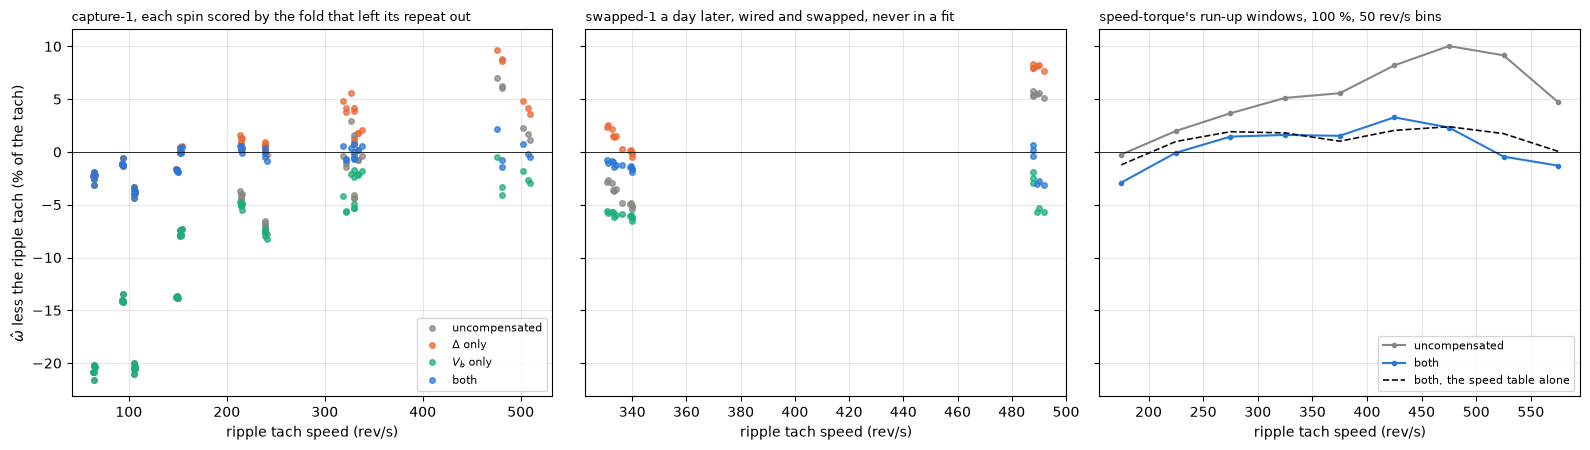

In [6]:
def binned(S, var, width=50):
    # the mean signed error in % per 50 rev/s of tach speed, for the run-up windows
    b = (S["truth"] // width) * width + width / 2
    e = (S[f"w_{var}"] - S["truth"]) / S["truth"] * 100
    g = e.groupby(b)
    return g.mean()[g.size() >= 5]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
panels = [("capture-1, each spin scored by the fold that left its repeat out", S_C1[S_C1["form"] == "table+d"]),
          ("swapped-1 a day later, wired and swapped, never in a fit", S_SW[S_SW["form"] == "table+d"]),
          ("speed-torque's run-up windows, 100 %, 50 rev/s bins", S_ST[(S_ST["form"] == "table+d") & (S_ST["part"] == "run-up")])]
for a, (title, S) in zip(ax, panels):
    for v in cp.VARIANTS:
        if "run-up" in title:
            if v in ("delta", "vb"):
                continue                                                # at 100 % Delta is 0: Delta only is uncompensated, both is V_b only
            m = binned(S, v)
            a.plot(m.index, m.to_numpy(), "-o", ms=3, color=VAR_COLOR[v], label=VAR_LABEL[v])
        else:
            e = (S[f"w_{v}"] - S["truth"]) / S["truth"] * 100
            a.plot(S["truth"], e, "o", ms=4, alpha=0.75, color=VAR_COLOR[v], label=VAR_LABEL[v])
    if "run-up" in title:
        m = binned(S_ST[(S_ST["form"] == "table") & (S_ST["part"] == "run-up")], "both")
        a.plot(m.index, m.to_numpy(), "--", color=INK, lw=1.2, label=r"both, the speed table alone")
    a.axhline(0, color=INK, lw=0.6); a.grid(alpha=0.3)
    a.set_xlabel("ripple tach speed (rev/s)"); a.set_title(title, loc="left", fontsize=9)
ax[0].set_ylabel(r"$\hat\omega$ less the ripple tach (% of the tach)")
ax[0].legend(fontsize=8, loc="lower right"); ax[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

Each dot is one spin, colored by variant. The run-up panel bins its one-turn windows by 50 rev/s of tach speed. The thing to see is that only blue, both terms together, stays near zero across the whole speed range.

With both compensations the estimate reads within 1.6 to 2.5 % rms of the ripple tach on every held-out set with the speed table, and 1.6 to 3.5 % with $k_d$.

- capture-1 by repeat reads -0.95 % mean and 1.62 % rms with the speed table, -0.88 % and 1.64 % with $k_d$, -0.93 % and 1.74 % with the power law. From 160 rev/s up it is under 0.65 % rms with the table, and the top band's mean is 0.00 %; with $k_d$ the bands from 160 to 350 rev/s read 0.39 and 0.52 % rms, the best of the three, and the top band 1.18 %. Under 160 rev/s every form sits 1.7 to 1.8 % low (see the rail term below).
- swapped-1 reads -1.53 and -1.99 % mean, 1.62 and 2.13 % rms with the table, and -1.40 and -1.27 %, 1.68 and 1.60 % with $k_d$. The bias is $V_b$ being smaller a day later (see the sittings below); $k_d$ takes about a third of it out of the swapped block.
- speed-torque's 1514 run-up windows, at 188 to 577 rev/s and 119 to 727 mA, read +1.71 % mean and 2.54 % rms with the table and +0.53 % and 3.04 % with $k_d$. Its 3883 settled windows read +1.30 % and 2.28 % with the table and -2.15 % and 3.49 % with $k_d$. So $V_b$ fitted on the free shaft holds with current flowing to about 2 % either way, high confidence, and the dropout form pays at 100 %, where the rate runs to 960 a second, twice the highest free spin (see the run-ups below).

Uncompensated, the estimate reads low at low speed, 17.4 % at 0 to 100 rev/s and 14.0 % at 100 to 160, and high at the top, +4.1 % at 450 to 600 rev/s on capture-1 and +8.3 to +8.8 % on the run-ups. Either term alone can make it worse. On capture-1's 250 to 350 rev/s band the uncompensated estimate reads -0.98 %, $\Delta$ only +2.88 % and $V_b$ only -3.60 %. On swapped-1 wired, all bands, the rms goes from 4.61 % uncompensated to 4.95 % with $\Delta$ only and 5.48 % with $V_b$ only, and 1.62 % with both.

Held out against in-sample on capture-1, both compensations, the table's rms is 1.62 % against the published fit's 1.59 %. The three forms part where they extrapolate. The power law loses on capture-1's top band (1.10 against 0.64 % rms) and on the settled windows (2.83 against 2.28 %). The table with $k_d$ wins on capture-1 from 160 to 350 rev/s and on the swapped block, and loses on the run-ups and the settled windows. The result file carries every row of the table above.


## Reference constants against identified constants

The same estimator, both compensations, on the constants identification recovers board-only. Column A is the headline above with $V_b$ as the speed table. Column B keeps the reference $R$, $K_e$ and $\Delta$ and takes $V_b$ from one repeat's six minimal spins over 50 ms windows, three passes. Column C takes every constant from the board, 36 passes. To split C's price by constant, each identified constant also goes into B alone, B+R, B+Ke, B+Delta and B+L. A+d and C+d are A and C with $V_b$ as the table with $k_d$, the six spins giving $k_d$ too. capture-1 scores the two repeats a pass never read, and swapped-1 and speed-torque were never in any fit. Each pass's pieces come from identification's module and are checked against its result file first.


In [7]:
# the constants identification recovers board-only, per pass, from identification's own pieces
RRN = idn.rest_resistance_cells()                                       # rest-resistance's cells, run unchanged
R_SEAT = RRN["HOLE"]["r_plus"].to_dict()                                # one seat's R, the mean of its two graded laps
KE_REP = {rep: float((g["e_win"] / (2 * np.pi * g["coast_rev_s"])).mean()) for rep, g in C1.groupby("repeat")}   # 20 coasts
INN = idn.inductance_cells()                                            # inductance's cells, run unchanged
C2 = INN["C2"]
L_SEAT = (C2[C2["group"] == "g1-fwd-25"].groupby("hole")["l_mh"].median() * 1e-3).to_dict()   # 4 bursts at 25 % forward
REV0 = idn.runup_windows()[0]
ST = TB["speed-torque"].copy()
ST = ST.merge(idn.cut_slopes(REV0, ST), on=["k", "dir"])
ST["i100"] = ST["i_crest_50"]                                           # at 100 % the crest is the mean current
CALL = idn.c_per_cut(ST)                                                # c at each cut, by the 5 ms windows and the pinned read
CR = {rep: {x: float(CALL[x][(ST["repeat"] == rep).to_numpy()].mean()) for x in idn.ANCHOR_READS} for rep in sorted(ST["repeat"].unique())}
TABS50 = {rep: idn.f_from(idn.anchor_delta(TB["capture-1"][TB["capture-1"]["repeat"] == rep].copy(), CR[rep], SL, "capture-1", pre=50))[0]
          for rep in CR}                                                # one repeat's 20 spins with that pass's c, 50 ms windows
# each piece against identification's result file, so the passes are the ones identification graded
assert np.isclose(np.median(list(KE_REP.values())), IDR["ke_v_s_per_rad"]["value"]) and np.isclose(min(KE_REP.values()), IDR["ke_v_s_per_rad"]["lo"])
assert np.isclose(min(R_SEAT.values()), IDR["r_one_seat_ohm"]["lo"]) and np.isclose(max(R_SEAT.values()), IDR["r_one_seat_ohm"]["hi"])
assert np.isclose(min(L_SEAT.values()) * 1e3, IDR["l_mh"]["lo"]) and np.isclose(max(L_SEAT.values()) * 1e3, IDR["l_mh"]["hi"])
for d in (15, 20, 30, 40, 60):
    v = [np.interp(d, *TABS50[k]) for k in TABS50]
    assert np.isclose(np.median(v), IDR["delta_f_ma_per_v"][f"{d} %"]["value"]) and np.isclose(min(v), IDR["delta_f_ma_per_v"][f"{d} %"]["lo"])
print("every pass constant reproduces identification's result file")
print("R by seat " + ", ".join(f"{k}:{v:.3f}" for k, v in R_SEAT.items()) + " ohm")
print("Ke by repeat " + ", ".join(f"{k}:{v * 1e3:.5f}" for k, v in KE_REP.items()) + " mV s/rad")
print("L by seat " + ", ".join(f"{k}:{v * 1e3:.3f}" for k, v in L_SEAT.items()) + " mH")
for rep, (d, v) in TABS50.items():
    print(f"f(D) by the anchor, pass {rep}: " + ", ".join(f"{a:g} {b:.3f}" for a, b in zip(d, v) if 0 < a < 100) + " mA/V")

every pass constant reproduces identification's result file
R by seat 0:4.384, 1:4.453, 2:4.443, 3:4.407, 4:4.450, 5:4.486, 6:4.492, 7:4.531, 8:4.510, 9:4.458, 10:4.445, 11:4.497 ohm
Ke by repeat 0:1.16879, 1:1.16832, 2:1.16802 mV s/rad
L by seat 0:0.826, 1:0.819, 2:0.836, 3:0.771, 4:0.809, 5:0.821, 6:0.838, 7:0.785, 8:0.824, 9:0.812, 10:0.831, 11:0.774 mH
f(D) by the anchor, pass 0: 15 3.479, 20 3.620, 30 3.296, 40 3.313, 60 2.585 mA/V
f(D) by the anchor, pass 1: 15 3.464, 20 3.475, 30 3.306, 40 3.338, 60 2.665 mA/V
f(D) by the anchor, pass 2: 15 3.904, 20 4.205, 30 3.966, 40 3.872, 60 2.657 mA/V


In [8]:
# the passes: A the reference constants (the headline above), B reference R, Ke and Delta with V_b from one repeat's six
# minimal spins, C every constant identified, and each identified constant alone in B
def make(rep, seat=None, r="ref", ke="ref", delta="ref", l="ref", dropouts=False):
    tr = C1[C1["repeat"] == rep]
    trv = tr[cp.in_rungs(tr, idn.MIN_RUNGS)]                            # 7.4 V 30, 40, 60 % both ways, one repeat
    R_ = R_SEAT[seat] if r == "seat" else cp.R_LOCKED
    P = dict(r=R_, ke=KE_REP[rep] if ke == "rep" else cp.KE, l_h=L_SEAT[seat] if l == "seat" else L_H)
    kw = dict(pre=50, ke=P["ke"], dropouts=dropouts)                     # V_b from the six spins: the speed table, with k_d only where asked
    if delta == "ref":
        P.update(ftab=FT_PUB, ftab_c1=FT_HELD, fit=cp.vb_fit(trv, FT_PUB, R_, **kw), fit_c1=cp.vb_fit(trv, FT_HELD, R_, **kw))
    else:                                                               # the anchor's table, one pass's c and one repeat
        P.update(ftab=TABS50[rep], ftab_c1=TABS50[rep], fit=cp.vb_fit(trv, TABS50[rep], R_, **kw))
    return P

rows = []
for rep in sorted(C1["repeat"].unique()):
    test = C1[C1["repeat"] != rep]                                      # capture-1 scores the two repeats the pass never read
    run = lambda tag, P, seat=None: rows.extend(cp.flat(cp.score_pass(test, SW, RU, RS, P), tag=tag, rep=rep, seat=seat))
    run("B", make(rep)); run("B+Ke", make(rep, ke="rep")); run("B+Delta", make(rep, delta="anchor"))
    for s in sorted(R_SEAT):
        run("B+R", make(rep, s, r="seat"), s); run("B+L", make(rep, s, l="seat"), s)
        run("C", make(rep, s, r="seat", ke="rep", delta="anchor", l="seat"), s)
        run("C+d", make(rep, s, r="seat", ke="rep", delta="anchor", l="seat", dropouts=True), s)   # every constant identified, V_b with k_d
# A: the reference headline, V_b as the speed table, and A+d the same with k_d, from the scores above
for lab, cap in (("capture-1 CV", "capture-1"), ("swapped-1 wired", "swapped-1 wired"), ("swapped-1 swapped", "swapped-1 swapped"),
                 ("speed-torque run-up", "speed-torque run-up"), ("speed-torque settled", "speed-torque settled")):
    S, sel = [(S, sel) for l_, S, sel in HELD if l_ == lab][0]
    for tag, form in (("A", "table"), ("A+d", "table+d")):
        g = S[S["form"] == form]
        g = g[g[sel[0]] == sel[1]] if sel else g
        rows.extend(dict(tag=tag, rep=None, seat=None, capture=cap, **b.to_dict()) for _, b in cp.bands(g).iterrows())
E2E = pd.DataFrame(rows)
print("passes per tag: " + ", ".join(f"{t} {n}" for t, n in E2E.drop_duplicates(["tag", "rep", "seat"]).groupby("tag").size().items()))
SUM = {t: cp.summarize(g) for t, g in E2E.groupby("tag")}
out = []
for cap in cp.CAPS:
    for band in cp.BAND_ORDER:
        if band not in set(SUM["C"][SUM["C"]["capture"] == cap]["band"]):
            continue
        a, b, c, ad, cd = (SUM[t].set_index(["capture", "band"]).loc[(cap, band)] for t in ("A", "B", "C", "A+d", "C+d"))
        out.append(dict(capture=cap, band=band, n=int(c["n"]), A=f"{a['mean_pct']:+.2f} / {a['rms_pct']:.2f}",
                        B=f"{b['mean_pct']:+.2f} / {b['rms_pct']:.2f} [{b['rms_lo']:.2f}-{b['rms_hi']:.2f}]",
                        C=f"{c['mean_pct']:+.2f} / {c['rms_pct']:.2f} [{c['rms_lo']:.2f}-{c['rms_hi']:.2f}]", C_less_A=round(c["rms_pct"] - a["rms_pct"], 2),
                        A_d=f"{ad['mean_pct']:+.2f} / {ad['rms_pct']:.2f}",
                        C_d=f"{cd['mean_pct']:+.2f} / {cd['rms_pct']:.2f} [{cd['rms_lo']:.2f}-{cd['rms_hi']:.2f}]", C_d_less_A_d=round(cd["rms_pct"] - ad["rms_pct"], 2)))
print("both compensations, mean signed error / rms %, B and C the median pass [rms range over the passes]; A, B, C with V_b as the speed table, A_d and C_d with k_d")
print(pd.DataFrame(out).to_string(index=False))
for t in ("B", "B+Delta", "C", "C+d"):
    g = E2E[(E2E["tag"] == t) & (E2E["capture"] == "capture-1") & (E2E["band"] == "all")].groupby("rep")["rms_pct"].median()
    print(f"capture-1, all bands, {t:8s} rms by repeat (the median over the seats): " + ", ".join(f"{int(k)} {v:.2f}" for k, v in g.items()) + " %")
print("\nthe price by constant, all bands, median pass mean / rms % [rms range]:")
for cap in cp.CAPS:
    print(f"  {cap:21s} " + " | ".join(
        f"{t} {x['mean_pct']:+.2f} / {x['rms_pct']:.2f} [{x['rms_lo']:.2f}-{x['rms_hi']:.2f}]"
        for t in ("A", "B", "B+R", "B+Ke", "B+Delta", "B+L", "C", "A+d", "C+d") for x in [SUM[t].set_index(["capture", "band"]).loc[(cap, "all")]]))

passes per tag: A 1, A+d 1, B 3, B+Delta 3, B+Ke 3, B+L 36, B+R 36, C 36, C+d 36
both compensations, mean signed error / rms %, B and C the median pass [rms range over the passes]; A, B, C with V_b as the speed table, A_d and C_d with k_d
             capture    band    n            A                        B                        C  C_less_A          A_d                      C_d  C_d_less_A_d
           capture-1   0-100    8 -1.72 / 1.86 -1.75 / 1.93 [1.65-1.97] -2.77 / 2.84 [0.95-3.74]      0.99 -1.72 / 1.86 -2.77 / 2.84 [0.95-3.74]          0.99
           capture-1 100-160   12 -1.82 / 2.44 -1.78 / 2.45 [2.33-2.53] -2.75 / 3.23 [1.63-3.76]      0.80 -1.82 / 2.44 -2.75 / 3.23 [1.63-3.76]          0.80
           capture-1 160-250    8 -0.08 / 0.45 -0.01 / 0.54 [0.51-0.56] -0.01 / 0.64 [0.52-0.86]      0.19 +0.07 / 0.39 +0.06 / 0.64 [0.47-0.85]          0.25
           capture-1 250-350    8 -0.20 / 0.63 -0.05 / 0.68 [0.53-0.74] -0.17 / 0.77 [0.57-0.83]      0.14 -0.02 / 0.52 +0.55

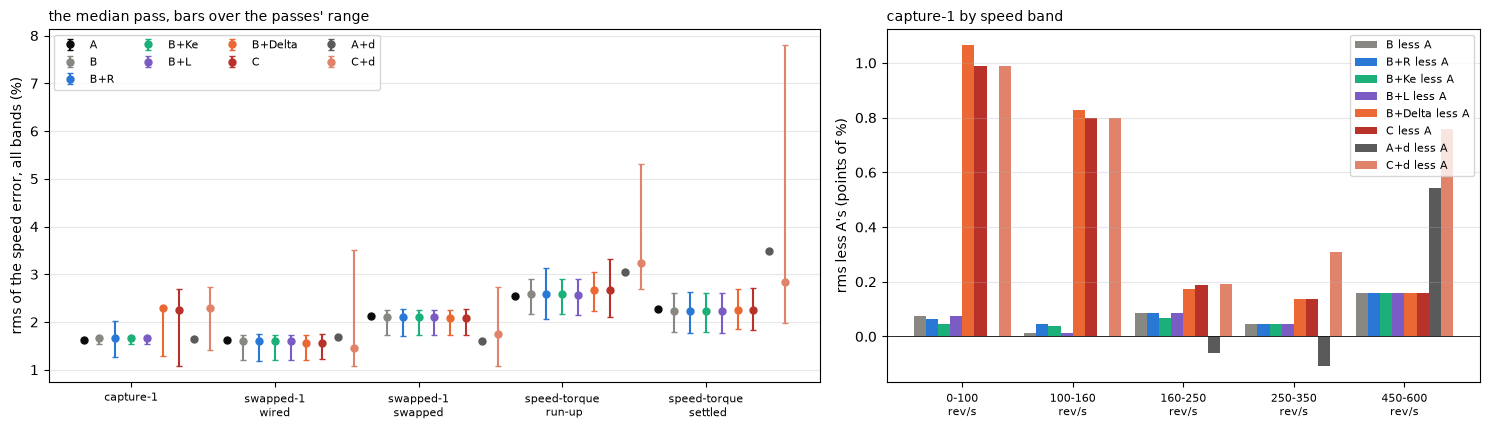

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
TAGS = [("A", INK), ("B", MUTED), ("B+R", BLUE), ("B+Ke", GREEN), ("B+L", "#7a5cc4"), ("B+Delta", ORANGE), ("C", "#b8322a"), ("A+d", "#5a5a5a"), ("C+d", "#e0836a")]
a = ax[0]
for j, (t, col) in enumerate(TAGS):
    s = SUM[t].set_index(["capture", "band"])
    x = np.arange(len(cp.CAPS)) + (j - 3) * 0.11
    y = [s.loc[(c, "all"), "rms_pct"] for c in cp.CAPS]
    lo = [s.loc[(c, "all"), "rms_lo"] for c in cp.CAPS]; hi = [s.loc[(c, "all"), "rms_hi"] for c in cp.CAPS]
    a.errorbar(x, y, yerr=[np.subtract(y, lo), np.subtract(hi, y)], fmt="o", color=col, ms=5, capsize=2, label=t)
a.set_xticks(range(len(cp.CAPS)), [c.replace("speed-torque", "speed-torque\n").replace("swapped-1 ", "swapped-1\n") for c in cp.CAPS], fontsize=8)
a.set_ylabel("rms of the speed error, all bands (%)"); a.grid(alpha=0.3, axis="y"); a.legend(fontsize=8, ncol=4)
a.set_title("the median pass, bars over the passes' range", loc="left", fontsize=10)
a = ax[1]
c1 = {t: SUM[t][SUM[t]["capture"] == "capture-1"].set_index("band") for t, _ in TAGS}
bl = [b for b in cp.BAND_ORDER if b in c1["C"].index and b != "all"]
for j, (t, col) in enumerate(TAGS[1:]):
    a.bar(np.arange(len(bl)) + (j - 3.5) * 0.11, [c1[t].loc[b, "rms_pct"] - c1["A"].loc[b, "rms_pct"] for b in bl], 0.11, color=col, label=f"{t} less A")
a.axhline(0, color=INK, lw=0.6); a.grid(alpha=0.3, axis="y")
a.set_xticks(range(len(bl)), [f"{b}\nrev/s" for b in bl], fontsize=8); a.set_ylabel("rms less A's (points of %)")
a.set_title("capture-1 by speed band", loc="left", fontsize=10); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

On the left, the all-band rms for each capture, the dot the median pass and the bar the range over the passes. On the right, capture-1's rms by band less A's. The thing to see is that only the orange and red medians move on capture-1, $\Delta$ by the anchor alone and C, and that they move under 160 rev/s.

Every constant from the board gives 2.25 % rms on capture-1, 1.56 and 2.08 % on swapped-1, 2.67 % on the run-ups and 2.25 % on the settled windows, the median pass. Against the reference constants that is +0.63, -0.06, -0.05, +0.13 and -0.03 points of rms.

The price on capture-1 is almost all $\Delta$ through the anchor. With every other constant at its reference, the anchor's $\Delta$ alone takes capture-1 from 1.67 to 2.29 %. It sits under 160 rev/s, where C reads -2.77 and -2.75 % against A's -1.72 and -1.82 %, and C's rms is 0.99 and 0.80 points over A's. Over 160 rev/s C is within 0.19 points of A. $R$ from one seat adds nothing in the median, with 1.26 to 2.03 % over the 36 passes. $K_e$ from one repeat and $L$ from one seat move nothing visible. By repeat, C reads 2.32, 2.29 and 1.27 % on capture-1 against B's 1.67, 1.54 and 1.69 %. So the price is the spread of one anchor pass, two passes high and one low, and with three passes its size is not resolved past about two sigma. Moderate confidence on the size, high confidence that it is $\Delta$.

B against A is the price of six spins of one repeat for $V_b$ against three repeats of all ten rungs: +0.05 points on capture-1, +0.04 on the run-ups, -0.03 and -0.02 on swapped-1, nothing. With $k_d$ the six spins also carry $k_d$, and C+d reads 2.30 % on capture-1 against A+d's 1.64, 1.46 and 1.74 % on swapped-1 against 1.68 and 1.60, 3.24 % on the run-ups against 3.04 and 2.84 % on the settled windows against 3.49, the median pass; its worst passes reach 3.5 % on the wired block and 7.8 % on the settled windows, where a $k_d$ read from six spins meets a dropout rate twice the one it was read at.


### R and temperature

The locked $R$ was read at one temperature. $R(T) = R_\mathrm{ref}\,(1 + \alpha\,(T - T_\mathrm{ref}))$ carries it to each spin's temperature, with $\alpha$ copper's 0.39 % per C, $T$ the board NTC at the spin's folder and $T_\mathrm{ref}$ the board at the stall pass's graded laps. The bare motor sits in the rig away from the board, so the NTC reads the board and the room. A third model adds the winding's own rise above it, bounded from rest-resistance's thermal numbers as identification bounds it. A and C are scored with $R$ fixed, by $R(T)$, and by $R(T)$ with the self-heat bound.

In [10]:
# R(T): the locked R carried to each spin's temperature by the board NTC, alone and with the winding's own rise bounded
ALPHA = idn.ALPHA_CU
folders = sorted(set(pd.concat([TB[k]["folder"] for k in ("capture-1", "speed-torque", "swapped-wired", "swapped-swapped")])))
NT = pd.DataFrame(mm.run_parallel([(idn.folder_ntc, (results.ROOT / f,), {}) for f in folders])).set_index("folder")
graded = RRN["S"][RRN["S"]["graded"] & (RRN["S"]["dir"] == 1)]           # the stall pass's graded laps, the reference R's temperature
T_REF = float(graded["board_c"].median())
T_SEAT = graded.groupby("hole")["board_c"].mean().to_dict()
WPJ = idn.RR["warming_pct_per_j"]["value"] / 100                        # the copper's warming per joule within a lap
BODY = float(RRN["best"]["slope"]) / 100                                # rest-resistance's one-body map, per joule held
TAU = idn.RR["hole_map_body_tau_s"]["value"]
HEAT = {}
for run in ("capture-1", "swapped-wired", "swapped-swapped"):
    T = TB[run]
    e_spin = (cp.R_LOCKED * (T["i_crest_200"] * 1e-3) ** 2 * T["spin_rows"] / cp.FS).to_numpy()   # an upper bound, the crest over-reads
    t = T["t_start"].to_numpy()
    carried = np.array([BODY * np.sum(e_spin[t < ti] * np.exp(-(ti - t[t < ti]) / TAU)) for ti in t])
    HEAT[run] = pd.Series(WPJ * e_spin + carried, index=T.index)
K_OF = dict(zip(TB["speed-torque"]["folder"], TB["speed-torque"]["k"]))
EN = {(int(K_OF[r_["folder"]]), int(r_["dir"])): r_ for p in mm.run_parallel([(idn.copper_joules, (results.ROOT / f,), {})
      for f in TB["speed-torque"]["folder"].unique()]) for r_ in p}       # the run-ups' copper joules from the drive's start
print(f"T_ref {T_REF:.2f} C; the winding's own rise at most {max(h.max() for h in HEAT.values()) * 100:.2f} % of R on a free spin")
for run in ("capture-1", "swapped-wired", "swapped-swapped", "speed-torque"):
    x = NT.loc[TB[run]["folder"].unique(), "ntc_c"]
    print(f"  {run:16s} board {x.min():.2f} to {x.max():.2f} C, R moves {ALPHA * (x.min() - T_REF) * 100:+.2f} to {ALPHA * (x.max() - T_REF) * 100:+.2f} %")

def r_rows(T, run, r_ref, t_ref, model):
    # R per spin under each model: fixed, by the board NTC, and by the NTC with the self-heat bound
    if model == "fixed":
        return np.full(len(T), r_ref)
    f = 1 + ALPHA * (NT.loc[T["folder"], "ntc_c"].to_numpy() - t_ref)
    return r_ref * f * ((1 + HEAT[run].loc[T.index].to_numpy()) if model == "R(T)+self" else 1)

def r_windows(W, r_ref, t_ref, model):
    if model == "fixed":
        return np.full(len(W), r_ref)
    fk = {int(K_OF[f]): NT.loc[f, "ntc_c"] for f in K_OF}
    f = 1 + ALPHA * (np.array([fk[int(k)] for k in W["k"]]) - t_ref)
    if model == "R(T)+self":
        f = f * (1 + WPJ * np.array([np.interp(t, EN[(int(k), int(d))]["t"], EN[(int(k), int(d))]["e"]) for k, d, t in zip(W["k"], W["dir"], W["t"])]))
    return r_ref * f

MODELS = ("fixed", "R(T)", "R(T)+self")
rows = []
for model in MODELS:
    # A: V_b on two repeats for capture-1, on all of capture-1 for the rest, every V_b read with that model's R
    parts = []
    for rep in range(3):
        tr, te = C1[C1["repeat"] != rep], C1[C1["repeat"] == rep]
        fit = cp.vb_fit(tr, FT_HELD, r=r_rows(tr, "capture-1", cp.R_LOCKED, T_REF, model), dropouts=False)
        parts.append(cp.score_spins(te, fit, FT_HELD, "capture-1", r=r_rows(te, "capture-1", cp.R_LOCKED, T_REF, model), form="table"))
    sc = {"capture-1": cp.bands(pd.concat(parts))}
    fit = cp.vb_fit(C1, FT_PUB, r=r_rows(C1, "capture-1", cp.R_LOCKED, T_REF, model), dropouts=False)
    for b, T in SW.items():
        sc[f"swapped-1 {b}"] = cp.bands(cp.score_spins(T, fit, FT_PUB, f"swapped-{b}", r=r_rows(T, f"swapped-{b}", cp.R_LOCKED, T_REF, model), form="table"))
    for lab, W in (("speed-torque run-up", RU), ("speed-torque settled", RS)):
        sc[lab] = cp.bands(cp.score_windows(W, fit, "table", r_windows(W, cp.R_LOCKED, T_REF, model)))
    rows += cp.flat(sc, tag="A", model=model)
    # C: the 36 identified passes, R and T_ref from the seat
    for rep in range(3):
        trv = C1[(C1["repeat"] == rep) & cp.in_rungs(C1, idn.MIN_RUNGS)]
        te = C1[C1["repeat"] != rep]
        for s in sorted(R_SEAT):
            r0, t0 = R_SEAT[s], T_SEAT[s]
            fit = cp.vb_fit(trv, TABS50[rep], r=r_rows(trv, "capture-1", r0, t0, model), pre=50, ke=KE_REP[rep], dropouts=False)
            sc = {"capture-1": cp.bands(cp.score_spins(te, fit, TABS50[rep], "capture-1", r=r_rows(te, "capture-1", r0, t0, model), ke=KE_REP[rep], form="table"))}
            for b, T in SW.items():
                sc[f"swapped-1 {b}"] = cp.bands(cp.score_spins(T, fit, TABS50[rep], f"swapped-{b}", r=r_rows(T, f"swapped-{b}", r0, t0, model), ke=KE_REP[rep], form="table"))
            for lab, W in (("speed-torque run-up", RU), ("speed-torque settled", RS)):
                sc[lab] = cp.bands(cp.score_windows(W, fit, "table", r_windows(W, r0, t0, model), KE_REP[rep], L_SEAT[s]))
            rows += cp.flat(sc, tag="C", model=model, rep=rep, seat=s)
RT = pd.DataFrame(rows)
RTS = RT.groupby(["tag", "model", "capture", "band"])[["mean_pct", "rms_pct"]].median().reset_index()
fx = RTS[RTS["model"] == "fixed"].set_index(["tag", "capture", "band"])["rms_pct"]
assert np.allclose(fx.loc["A"].loc[[(c, "all") for c in cp.CAPS]], [SUM["A"].set_index(["capture", "band"]).loc[(c, "all"), "rms_pct"] for c in cp.CAPS])
assert np.allclose(fx.loc["C"].loc[[(c, "all") for c in cp.CAPS]], [SUM["C"].set_index(["capture", "band"]).loc[(c, "all"), "rms_pct"] for c in cp.CAPS])
print("the fixed-R rows reproduce A and C above")
piv = RTS.assign(cell=[f"{a:+.2f} / {b:.2f}" for a, b in zip(RTS["mean_pct"], RTS["rms_pct"])]).pivot(index=["capture", "band"], columns=["tag", "model"], values="cell")
print(piv.reindex([(c, b) for c in cp.CAPS for b in cp.BAND_ORDER if (c, b) in piv.index]).to_string())

T_ref 25.67 C; the winding's own rise at most 0.37 % of R on a free spin
  capture-1        board 24.15 to 25.82 C, R moves -0.60 to +0.06 %
  swapped-wired    board 25.90 to 26.24 C, R moves +0.09 to +0.22 %
  swapped-swapped  board 26.35 to 26.35 C, R moves +0.26 to +0.26 %
  speed-torque     board 25.31 to 25.37 C, R moves -0.14 to -0.12 %


the fixed-R rows reproduce A and C above
tag                                      A                                         C                            
model                                 R(T)     R(T)+self         fixed          R(T)     R(T)+self         fixed
capture              band                                                                                       
capture-1            0-100    -1.54 / 1.68  -1.59 / 1.72  -1.72 / 1.86  -2.60 / 2.67  -2.65 / 2.72  -2.77 / 2.84
                     100-160  -1.78 / 2.40  -1.83 / 2.45  -1.82 / 2.44  -2.71 / 3.20  -2.77 / 3.25  -2.75 / 3.23
                     160-250  -0.08 / 0.46  -0.08 / 0.46  -0.08 / 0.45  +0.01 / 0.66  -0.01 / 0.67  -0.01 / 0.64
                     250-350  -0.20 / 0.64  -0.20 / 0.64  -0.20 / 0.63  -0.16 / 0.78  -0.15 / 0.78  -0.17 / 0.77
                     450-600  +0.00 / 0.64  +0.00 / 0.64  +0.00 / 0.64  +0.14 / 0.80  +0.14 / 0.79  +0.14 / 0.80
                     all      -0.90 / 1.57  -0.92 / 1.6

$R(T)$ moves no row's rms by more than 0.18 points. The largest moves are capture-1's 0 to 100 rev/s band, -1.72 to -1.54 % mean on A, and the run-up's 160 to 250 band, whose mean moves +0.22 points. The board moved $R$ by only -0.60 to +0.26 % across these sittings and the self-heat bound adds at most 0.37 %, because the bare motor sat near room temperature throughout. The residual biases do not follow it. capture-1's low band improves by about a fifth of what the 2 % test below says the free shaft wants. So these data show $R(T)$ moving nothing here, high confidence, and a warm winding is not in them.


### How few rungs for V_b

identification graded its $V_b$ subsets as constants, each table against the full-data table, and left the speed test to this notebook. Here each subset of one repeat's rungs, both ways, becomes $V_b$ in a pass that is otherwise column B, reference $R$, $K_e$ and $\Delta$. The rule was set before running. A subset holds if its median pass's all-band rms is within 0.2 points of column A on every held-out set.

A, all bands, rms %: capture-1 1.62, swapped-1 wired 1.62, swapped-1 swapped 2.13, speed-torque run-up 2.54, speed-torque settled 2.28

V_b over the last 200 ms, median pass's all-band rms % [range] per held-out set, and the rule (within 0.2 of A everywhere)
  all 10 rungs                 1.66 [1.53-1.70] | 1.62 [1.31-1.94] | 2.13 [1.81-2.45] | 2.57 [2.19-2.90] | 2.28 [1.93-2.69] | holds True
  7 rungs over 145 rev/s       1.66 [1.53-1.70] | 1.62 [1.31-1.94] | 2.13 [1.81-2.45] | 2.57 [2.19-2.90] | 2.28 [1.93-2.69] | holds True
  5 V 30/40/60 + 7.4 V 40/60   1.67 [1.58-2.22] | 1.69 [1.39-2.00] | 2.20 [1.89-2.51] | 2.57 [2.18-2.88] | 2.28 [1.93-2.69] | holds True
  7.4 V only, 5 rungs          1.68 [1.55-1.69] | 1.63 [1.21-1.71] | 2.15 [1.73-2.23] | 2.58 [2.18-2.89] | 2.23 [1.85-2.59] | holds True
  7.4 V 20/30/40/60            1.68 [1.55-1.69] | 1.63 [1.21-1.71] | 2.15 [1.73-2.23] | 2.58 [2.18-2.89] | 2.23 [1.85-2.59] | holds True
  7.4 V 30/40/60               1.67 [1.54-1.69] | 1.63 [

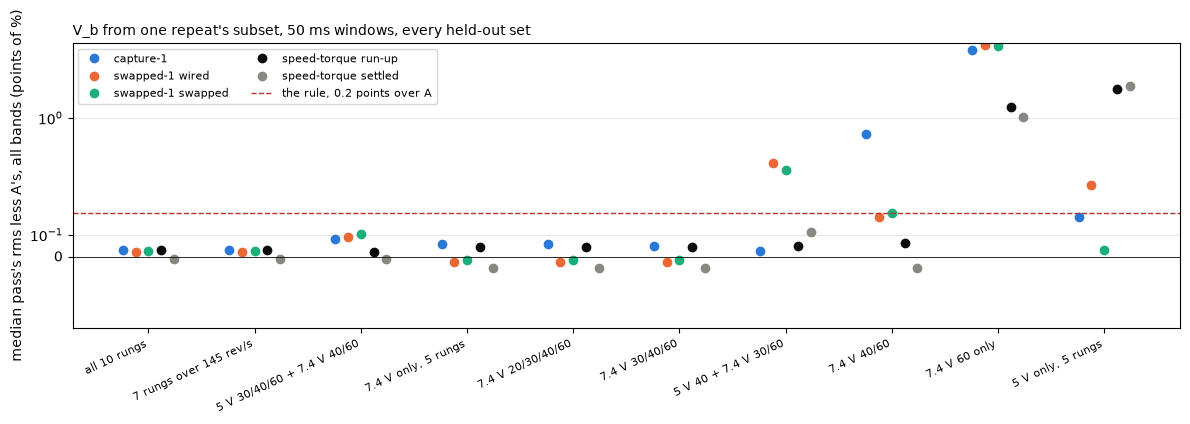

In [11]:
# the V_b subsets' held-out speed rule: reference R, Ke and Delta, V_b from one repeat's subset, scored like A
A_ALL = {c: SUM["A"].set_index(["capture", "band"]).loc[(c, "all"), "rms_pct"] for c in cp.CAPS}
rows = []
for pre in (200, 50):
    for lab, cells in cp.SUBSETS.items():
        for rep in range(3):
            tr = C1[(C1["repeat"] == rep) & cp.in_rungs(C1, cells)]
            assert len(tr) == 2 * len(cells)
            P = dict(r=cp.R_LOCKED, ke=cp.KE, l_h=L_H, ftab=FT_PUB, ftab_c1=FT_HELD,
                     fit=cp.vb_fit(tr, FT_PUB, pre=pre, dropouts=False), fit_c1=cp.vb_fit(tr, FT_HELD, pre=pre, dropouts=False))
            sc = cp.score_pass(C1[C1["repeat"] != rep], SW, RU, RS, P)
            rows += [dict(pre=pre, subset=lab, rep=rep, capture=c, rms_pct=sc[c].set_index("band").loc["all", "rms_pct"]) for c in cp.CAPS]
VS = pd.DataFrame(rows)
VSM = VS.groupby(["pre", "subset", "capture"], sort=False)["rms_pct"].agg(["median", "min", "max"]).reset_index()
VSM["over_A"] = VSM["median"] - VSM["capture"].map(A_ALL)
HOLDS = VSM.groupby(["pre", "subset"], sort=False)["over_A"].max().le(cp.SUBSET_RULE_PTS).rename("holds")
print("A, all bands, rms %: " + ", ".join(f"{c} {v:.2f}" for c, v in A_ALL.items()))
for pre in (200, 50):
    print(f"\nV_b over the last {pre} ms, median pass's all-band rms % [range] per held-out set, and the rule (within {cp.SUBSET_RULE_PTS} of A everywhere)")
    for lab in cp.SUBSETS:
        g = VSM[(VSM["pre"] == pre) & (VSM["subset"] == lab)].set_index("capture")
        print(f"  {lab:28s} " + " | ".join(f"{g.loc[c, 'median']:.2f} [{g.loc[c, 'min']:.2f}-{g.loc[c, 'max']:.2f}]" for c in cp.CAPS)
              + f" | holds {HOLDS.loc[(pre, lab)]}")
b50 = VSM[(VSM["pre"] == 50) & (VSM["subset"] == "7.4 V 30/40/60")].set_index("capture")["median"]
assert np.allclose(b50.loc[cp.CAPS], [SUM["B"].set_index(["capture", "band"]).loc[(c, "all"), "rms_pct"] for c in cp.CAPS])
print("\nthe minimal subset over 50 ms is column B above; its margin on A, points of rms: " + ", ".join(
    f"{c} {x:+.3f}" for c, x in VSM[(VSM["pre"] == 50) & (VSM["subset"] == "7.4 V 30/40/60")].set_index("capture")["over_A"].items()))

fig, ax = plt.subplots(figsize=(12, 4.2))
labs = list(cp.SUBSETS)
for j, c in enumerate(cp.CAPS):
    g = VSM[(VSM["pre"] == 50)].set_index(["subset", "capture"])
    ax.plot(np.arange(len(labs)) + (j - 2) * 0.12, [g.loc[(l_, c), "over_A"] for l_ in labs], "o", ms=6,
            color=[BLUE, ORANGE, GREEN, INK, MUTED][j], label=c)
ax.axhline(cp.SUBSET_RULE_PTS, color="#b8322a", lw=1, ls="--", label=f"the rule, {cp.SUBSET_RULE_PTS} points over A")
ax.axhline(0, color=INK, lw=0.6); ax.set_yscale("symlog", linthresh=0.5); ax.grid(alpha=0.3, axis="y")
ax.set_xticks(range(len(labs)), labs, fontsize=8, rotation=25, ha="right")
ax.set_ylabel("median pass's rms less A's, all bands (points of %)")
ax.set_title("V_b from one repeat's subset, 50 ms windows, every held-out set", loc="left", fontsize=10); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

Each subset's median pass, its rms less A's on each held-out set, over 50 ms windows, with the rule dashed. The thing to see is which subsets cross the line.

The fewest rungs that hold are three, 7.4 V at 30, 40 and 60 % both ways, six spins. All ten rungs, the seven over 145 rev/s, 5 V 30/40/60 with 7.4 V 40/60, and the three 7.4 V sets that keep 30, 40 and 60 % hold, and the 50 and 200 ms windows agree within 0.05 points. Without the 30 % rung (7.4 V 40/60) capture-1 rises to 2.30 %, since the table then holds the 330 rev/s rung's value all the way down to 150 rev/s. One rung alone reads 6.5 % on capture-1. 5 V alone has no rung past 340 rev/s and reads 4.5 % on the run-ups. "5 V 40 + 7.4 V 30/60" reads swapped-1 0.4 points over A. The minimal subset's margins on A are +0.05 points on capture-1 and +0.04 on the run-ups, inside the rule with room, so three rungs hold, moderate confidence from three passes.


## The tables

### f(D) per volt, and the rails

The reading term is one table for every rail only if the grid per volt does not depend on the rail.

rail    3.7    5.0    7.4    8.4   mean  spread_pct
duty                                               
10    3.670  3.677  3.693  3.700  3.685       0.818
15    3.777  3.796  3.830  3.843  3.812       1.735
20    3.842  3.870  3.920  3.938  3.892       2.467
30    3.830  3.870  3.935  3.957  3.898       3.276
40    3.631  3.672  3.735  3.757  3.699       3.398
50    3.268  3.301  3.352  3.369  3.323       3.047
60    2.772  2.793  2.826  2.837  2.807       2.323
70    2.180  2.188  2.202  2.207  2.194       1.216
80    1.529  1.524  1.522  1.523  1.525       0.421
90    0.849  0.837  0.825  0.822  0.834       3.224
the rail mean x rail less the grid, max |.| mA: 3.7 V 0.25, 5 V 0.14, 7.4 V 0.27, 8.4 V 0.50


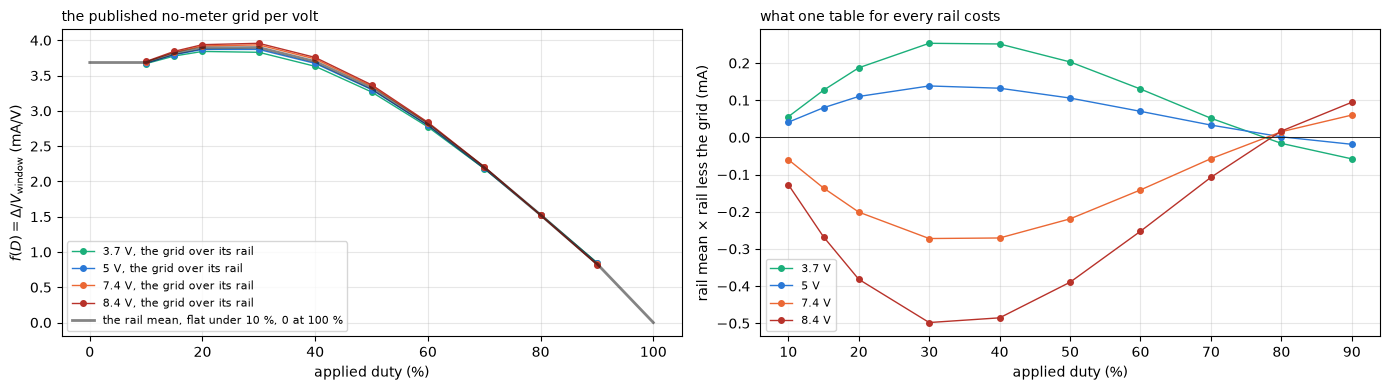

In [12]:
# f(D) per volt by rail, and what the rail mean costs at each rail
nm = GR[GR["loop"] == "no meter"].copy()
nm["f"] = nm["pub"] / nm["rail"]
FPIV = nm.pivot(index="duty", columns="rail", values="f")
FPIV["mean"] = FPIV[list(cp.RAILS)].mean(axis=1)
FPIV["spread_pct"] = (FPIV[list(cp.RAILS)].max(axis=1) - FPIV[list(cp.RAILS)].min(axis=1)) / FPIV["mean"] * 100
print(FPIV.round(3).to_string())
nm["mean_less_grid_ma"] = nm["duty"].map(FPIV["mean"]) * nm["rail"] - nm["pub"]
FD_COST = nm.groupby("rail")["mean_less_grid_ma"].apply(lambda x: x.abs().max())
print("the rail mean x rail less the grid, max |.| mA: " + ", ".join(f"{v:g} V {x:.2f}" for v, x in FD_COST.items()))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for v, col in zip(cp.RAILS, (GREEN, BLUE, ORANGE, "#b8322a")):
    h = nm[nm["rail"] == v]
    ax[0].plot(h["duty"], h["f"], "o-", ms=4, lw=1, color=col, label=f"{v:g} V, the grid over its rail")
    ax[1].plot(h["duty"], h["mean_less_grid_ma"], "o-", ms=4, lw=1, color=col, label=f"{v:g} V")
ax[0].plot(FT_PUB[0], FT_PUB[1], "-", color=INK, lw=2, alpha=0.5, label="the rail mean, flat under 10 %, 0 at 100 %")
ax[0].set_xlabel("applied duty (%)"); ax[0].set_ylabel(r"$f(D) = \Delta / V_\mathrm{window}$ (mA/V)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)
ax[0].set_title("the published no-meter grid per volt", loc="left", fontsize=10)
ax[1].axhline(0, color=INK, lw=0.6); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8)
ax[1].set_xlabel("applied duty (%)"); ax[1].set_ylabel(r"rail mean $\times$ rail less the grid (mA)")
ax[1].set_title("what one table for every rail costs", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

On the left, the grid per volt at each rail with the rail mean in gray. On the right, what the rail mean costs at each rail in mA. The thing to see is that the four rails lie within a few percent of one another, so one table per volt holds.

The rails spread 0.4 to 3.4 % of $f$ at a duty, widest at 30 to 50 %. The rail mean times the rail lands within 0.14 mA of the grid at 5.0 V, 0.25 at 3.7 V, 0.27 at 7.4 V and 0.50 at 8.4 V. On 3.7 to 7.4 V that is under 0.3 mA, 1.2 mV of $R\,i$, high confidence for the model's grid. The 3.7 and 8.4 V rails were never spun, so their grid is the model's and not a measurement. $f(D)$ runs 3.69, 3.81, 3.89, 3.90, 3.70, 3.32, 2.81, 2.19, 1.53 and 0.83 mA/V at 10 to 90 %.

### V_b by mechanical direction, the three forms

The three forms are fitted to capture-1's rung means, all three repeats with the published grid, the fits swapped-1 and speed-torque are scored on.


 level  duty  mech  rev_s     x   sd  n  dropouts  power  table  speed_part  table_d   se  res_power  res_table  res_table_d  z_power
   5.0    15    -1   65.0  -9.0  1.6  3       0.0    0.1    0.0         0.0      0.0  0.9       -9.1       -9.0         -9.0    -10.0
   5.0    20    -1   93.8  -5.8  2.9  3       0.0    0.3    0.0         0.0      0.0  1.7       -6.1       -5.8         -5.8     -3.6
   7.4    15    -1  105.6 -26.1  2.7  3       0.0    0.5    0.0         0.0      0.0  1.5      -26.5      -26.1        -26.1    -17.2
   7.4    20    -1  148.8 -16.8  0.8  3       0.0    1.7    0.0         0.0      0.0  0.5      -18.5      -16.8        -16.8    -39.8
   5.0    30    -1  153.4   3.0  3.7  3       0.0    1.9    0.7         0.7      0.7  2.2        1.2        2.3          2.3      0.5
   5.0    40    -1  214.5  13.1  4.3  3       0.0    6.4    9.4         9.4      9.4  2.5        6.7        3.7          3.7      2.7
   7.4    30    -1  239.8   4.1  7.8  3       0.0    9.5    7.

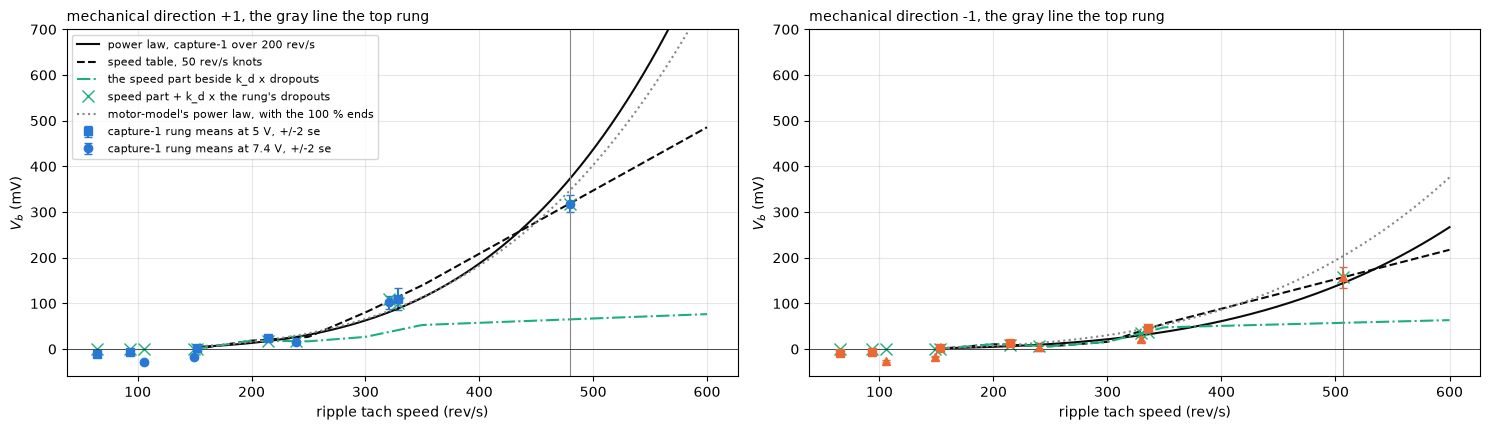

In [13]:
# the V_b rung means against the three forms, and the forms against each other
RM = cp.rung_means(C1, cp.vb_measured(C1, FT_PUB))
RM["dropouts"] = cp.rung_means(C1, cp.signals(C1, FT_PUB)["dropouts"])["x"]
RM["power"] = [cp.vb_eval(FIT_S, int(m), np.array([w]), "power")[0] for m, w in zip(RM["mech"], RM["rev_s"])]
RM["table"] = [cp.vb_eval(FIT_S, int(m), np.array([w]), "table")[0] for m, w in zip(RM["mech"], RM["rev_s"])]
RM["speed_part"] = [cp.vb_eval(FIT, int(m), np.array([w]), "table")[0] for m, w in zip(RM["mech"], RM["rev_s"])]
RM["table_d"] = RM["speed_part"] + FIT["k_d"] * RM["dropouts"]
RM["se"] = RM["sd"] / np.sqrt(RM["n"])
RM["res_power"], RM["res_table"], RM["res_table_d"] = RM["x"] - RM["power"], RM["x"] - RM["table"], RM["x"] - RM["table_d"]
RM["z_power"] = RM["res_power"] / RM["se"]
print(RM.sort_values(["mech", "rev_s"]).round(1).to_string(index=False))
for c in ("res_power", "res_table", "res_table_d"):
    h = RM[RM["rev_s"] > 200]
    print(f"  {c:12s} over the rungs above 200 rev/s: rms {cp.rms(h[c]):.1f} mV; the direction split, mech +1 less -1, at 7.4 V 40 and 60 % and 5 V 60 %: "
          + ", ".join(f"{(h[(h.level == lv) & (h.duty == du) & (h.mech == 1)][c].iloc[0] - h[(h.level == lv) & (h.duty == du) & (h.mech == -1)][c].iloc[0]):+.0f}"
                      for lv, du in ((7.4, 40), (7.4, 60), (5.0, 60))) + " mV")
ww = np.arange(200, 561, 40.0)
for m in (1, -1):
    d = cp.vb_eval(FIT_S, m, ww, "table") - cp.vb_eval(FIT_S, m, ww, "power")
    print(f"table less power law, mech {m:+d}, mV: " + ", ".join(f"{w:.0f} {x:+.0f}" for w, x in zip(ww, d)))
LOW = RM[RM["rev_s"] < 160]
print(f"under 160 rev/s: rung means {LOW['x'].min():+.1f} to {LOW['x'].max():+.1f} mV; 5 V rungs mean {LOW[LOW['level'] == 5.0]['x'].mean():+.1f}, "
      f"7.4 V {LOW[LOW['level'] == 7.4]['x'].mean():+.1f} mV; their se {LOW['se'].min():.1f} to {LOW['se'].max():.1f} mV")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
wf = np.linspace(150, 600, 200)
for a, m in zip(ax, (1, -1)):
    h = RM[RM["mech"] == m]
    for lv, mk in ((5.0, "s"), (7.4, MARK[m])):
        hh = h[h["level"] == lv]
        a.errorbar(hh["rev_s"], hh["x"], yerr=2 * hh["se"], fmt=mk, color=MECH_COLOR[m], capsize=3, ms=6, label=f"capture-1 rung means at {lv:g} V, +/-2 se")
    a.plot(wf, cp.vb_eval(FIT_S, m, wf, "power"), color=INK, lw=1.5, label="power law, capture-1 over 200 rev/s")
    a.plot(wf, cp.vb_eval(FIT_S, m, wf, "table"), "--", color=INK, lw=1.5, label="speed table, 50 rev/s knots")
    a.plot(wf, cp.vb_eval(FIT, m, wf, "table"), "-.", color=GREEN, lw=1.5, label="the speed part beside k_d x dropouts")
    hh = RM[RM["mech"] == m]
    a.plot(hh["rev_s"], hh["table_d"], "x", color=GREEN, ms=8, label="speed part + k_d x the rung's dropouts")
    a.plot(wf, cp.vb_eval(FITS_S["published"], m, wf, "power"), ":", color=MUTED, lw=1.5, label="motor-model's power law, with the 100 % ends")
    a.axvline(h["rev_s"].max(), color=MUTED, lw=0.8); a.axhline(0, color=INK, lw=0.5)
    a.set_ylim(-60, 700); a.grid(alpha=0.3); a.set_xlabel("ripple tach speed (rev/s)"); a.set_ylabel(r"$V_b$ (mV)")
    a.set_title(f"mechanical direction {m:+d}, the gray line the top rung", loc="left", fontsize=10)
ax[0].legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

Each direction's rung means with $\pm$2 standard errors, squares at 5 V, the power law solid, the speed table dashed, the speed part beside $k_d$ dash-dotted in green with the crosses adding $k_d$ times each rung's dropouts, and motor-model's power law dotted, the gray line at the top rung. The thing to see is how the three forms part past the top rung, and how little of the rung means the green speed part has to carry.

Without the 100 % ends and against the tach the exponent rises from motor-model's 3.5 to 3.8 (mech +1) and 3.6 (mech -1). Under 260 rev/s the power law and the table agree within 5 mV. Past the last rung the table sits 55 to 242 mV under the law at 480 to 560 rev/s in mech +1 and within 16 mV in mech -1, where both extrapolate.

The power law does not fit capture-1's own rungs over 300 rev/s. In mech +1 it misses 7.4 V 60 % by -54 mV (z -5.6) and 7.4 V 40 % by +22 mV (z +3.1), and in mech -1 5 V 60 % by +15 mV (z +5.0) and 7.4 V 40 % by -9 mV (z -4.0). The table passes through the rungs it has knots near, but its linear segments miss the rungs between knots by up to 18 mV, -18 mV at 7.4 V 40 % mech -1 and -10 mV at 7.4 V 30 % mech +1. Over the rungs above 200 rev/s the three forms leave 21.1, 7.0 and 6.5 mV rms. What the dropout term does shows in the direction split: at 7.4 V 40 and 60 % and 5 V 60 %, the three rungs where one direction drops out, the residual splits by +30, -66 and +7 mV under the power law, +16, 0 and -7 under the table, and +6, 0 and +1 with $k_d$, so the split between the directions is the dropout rate, not the speed. High confidence on the power law's misfit and on the split.

Under 160 rev/s every form puts zero, while the rung means there are -28.6 to +3.1 mV, -4.2 mV on average at 5 V and -22.2 mV at 7.4 V, with standard errors of 0.2 to 2.2 mV. That is the rail term below.


## Findings

### V_b follows the motor's rotation

bemf-coast put the speed split and the ripple dropouts in the motor, since the slower, opening direction followed the rotor across the lead swap. swapped-1 asks the same of $V_b$. Its measured $V_b$ by board direction is set against capture-1's power law under two mappings, the mechanical one, where a lead swap flips the table, and the board one, where the table follows the drive's sign.

  block  duty  board  n  rev_s    vb  se  dropouts  pred_mech  pred_board  speed_part  dropout_part
  wired    40     -1  3  331.4  57.4 2.0      71.7       91.6        30.9        43.1          37.6
  wired    40      1  3  338.6   2.7 2.5       0.0       33.4        99.4        40.4           0.0
  wired    60     -1  3  489.1 295.6 2.1     570.0      401.7       127.0        66.0         298.8
swapped    40     -1  3  339.7  -3.7 4.0       0.0       33.8        33.8        41.1           0.0
swapped    40      1  3  333.4  36.2 1.1      45.0       93.7        93.7        44.1          23.6
swapped    60      1  3  489.2 282.4 2.7     478.3      402.0       402.0        66.0         250.7
wired 40 %, board -1 less board +1: measured +54.7 +/- 3.3 mV, mechanical mapping +58.1, board mapping -68.4; with k_d the split is +2.6 mV of speed part and +37.6 mV of dropouts (72 against 0 per s)
mapping mech : measured less predicted V_b over 18 gated swapped-1 spins, mean -64.3 mV, rms 73.7 mV

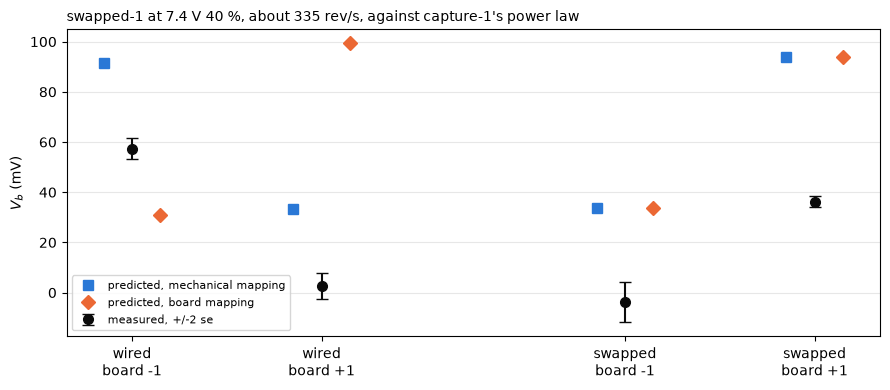

In [14]:
# which direction V_b follows: swapped-1's measured V_b by board direction against the capture-1 power law under each mapping
rows = []
for block in ("wired", "swapped"):
    run = f"swapped-{block}"
    T = TB[run]
    okw, _ = cp.tach_gate(T)
    x = cp.vb_measured(T, FT_PUB)
    for (du, d), g in T[okw].groupby(["duty", "dir"]):
        w = g["spin_rev_s"].mean()
        dr = g["dropouts_per_s"].mean()
        rows.append(dict(block=block, duty=du, board=d, n=len(g), rev_s=w, vb=x[g.index].mean(), se=x[g.index].std(ddof=1) / np.sqrt(len(g)),
                         dropouts=dr, pred_mech=cp.vb_eval(FIT_S, d * cp.MECH[run], np.array([w]), "power")[0],
                         pred_board=cp.vb_eval(FIT_S, d, np.array([w]), "power")[0],
                         speed_part=cp.vb_eval(FIT, d * cp.MECH[run], np.array([w]), "table")[0], dropout_part=FIT["k_d"] * dr))
MAP = pd.DataFrame(rows)
print(MAP.round(1).to_string(index=False))
w40 = MAP[(MAP["block"] == "wired") & (MAP["duty"] == 40)].set_index("board")
SPLIT = dict(measured=w40.loc[-1, "vb"] - w40.loc[1, "vb"], se=np.hypot(w40.loc[-1, "se"], w40.loc[1, "se"]),
             mech=w40.loc[-1, "pred_mech"] - w40.loc[1, "pred_mech"], board=w40.loc[-1, "pred_board"] - w40.loc[1, "pred_board"],
             speed_part=w40.loc[-1, "speed_part"] - w40.loc[1, "speed_part"], dropout_part=w40.loc[-1, "dropout_part"] - w40.loc[1, "dropout_part"])
print(f"wired 40 %, board -1 less board +1: measured {SPLIT['measured']:+.1f} +/- {SPLIT['se']:.1f} mV, mechanical mapping {SPLIT['mech']:+.1f}, "
      f"board mapping {SPLIT['board']:+.1f}; with k_d the split is {SPLIT['speed_part']:+.1f} mV of speed part and {SPLIT['dropout_part']:+.1f} mV of "
      f"dropouts ({w40.loc[-1, 'dropouts']:.0f} against {w40.loc[1, 'dropouts']:.0f} per s)")
MAP_SPEED = {}
for mapping in ("mech", "board"):
    res, sp = [], []
    for block in ("wired", "swapped"):
        run = f"swapped-{block}"
        T = cp.tag_mech(TB[run], run, mapping)
        okw, _ = cp.tach_gate(T)
        x = cp.vb_measured(T, FT_PUB)[okw]
        res.append(x.to_numpy() - cp.vb_eval(FIT_S, T["mech"][okw].to_numpy(), T["spin_rev_s"][okw].to_numpy(), "power"))
        S = cp.score_spins(T[okw.to_numpy()], FIT_S, FT_PUB, run, form="power")
        if block == "wired":
            MAP_SPEED[mapping] = cp.score_table(S[S["duty"] == 40], ["dir"], variants=("both",)).set_index("dir")["both_pct"].to_dict()
    res = np.concatenate(res)
    print(f"mapping {mapping:5s}: measured less predicted V_b over {len(res)} gated swapped-1 spins, mean {res.mean():+.1f} mV, rms {cp.rms(res):.1f} mV; "
          f"wired 40 % speed error, both, by board dir " + ", ".join(f"{k:+d} {v:+.2f} %" for k, v in MAP_SPEED[mapping].items()))

fig, ax = plt.subplots(figsize=(9, 4))
for j, (block, du) in enumerate((("wired", 40), ("swapped", 40))):
    h = MAP[(MAP["block"] == block) & (MAP["duty"] == du)].set_index("board")
    for k, d in enumerate((-1, 1)):
        x0 = j * 2.6 + k
        ax.errorbar(x0, h.loc[d, "vb"], yerr=2 * h.loc[d, "se"], fmt="o", color=INK, ms=7, capsize=4, label="measured, +/-2 se" if x0 == 0 else None)
        ax.plot(x0 - 0.15, h.loc[d, "pred_mech"], "s", color=BLUE, ms=7, label="predicted, mechanical mapping" if x0 == 0 else None)
        ax.plot(x0 + 0.15, h.loc[d, "pred_board"], "D", color=ORANGE, ms=7, label="predicted, board mapping" if x0 == 0 else None)
ax.set_xticks([0, 1, 2.6, 3.6], ["wired\nboard -1", "wired\nboard +1", "swapped\nboard -1", "swapped\nboard +1"])
ax.set_ylabel(r"$V_b$ (mV)"); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
ax.set_title("swapped-1 at 7.4 V 40 %, about 335 rev/s, against capture-1's power law", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

Black is measured, blue the prediction keyed by mechanical direction and orange the one keyed by board direction, both from the speed-only power law. In the swapped block the two mappings coincide, by construction. The thing to see is the wired block, where they point opposite ways and the measured split follows blue.

At 7.4 V 40 % in the wired block, board -1 reads 54.7 $\pm$ 3.3 mV over board +1. The mechanical mapping predicts +58.1 mV and the board mapping -68.4 mV. In speed the mechanical mapping leaves both wired directions at about -1.2 %, the board mapping +1.0 and -3.4 %. So at 40 % $V_b$ follows the motor's mechanical rotation and not the board's drive sign, high confidence on the sign of that split, from three spins per cell. It is the only duty where both wired directions survive the tach gate, so it is one duty's test. bemf-coast's speed split and ripple dropouts followed the rotor across the same swap.

With $k_d$ the same split reads +2.6 mV of speed part and +37.6 mV of dropouts, 72 a second in board -1 against none in board +1. The direction the table has to know is the direction that drops out, and the board counts that itself, so the mechanical mapping matters for the speed part alone, which the two directions share within a few millivolts at this speed. A table keyed by mechanical direction still needs the leads' orientation, and a lead swap flips it; the dropout count does not.

Over all 18 gated spins the two mappings do not separate, measured less predicted -64.3 mV mean and 73.7 mV rms (mechanical) against -19.4 and 98.1 mV (board). The 60 % cells own that. The wired 60 % cell, board -1, reads 296 mV against 402 mechanical and 127 board, between the two, and its other direction was gated out. Every 10-29 cell sits under the 10-28 fit, which is the next finding, and at 60 % that drop is as large as the split itself.


### V_b between the two sittings

capture-1 ran on 10-28 and swapped-1 on 10-29. One motor lead broke and was replaced between the two sittings, so the motor's terminals are not the same terminals on both days.

In [15]:
# V_b on 10-29 (swapped-1) against the 10-28 fit (capture-1), by mechanical direction
rows = []
for block in ("wired", "swapped"):
    T = SW[block]
    x = cp.vb_measured(T, FT_PUB)
    for (du, m), g in T.groupby(["duty", "mech"]):
        pp = cp.vb_eval(FIT_S, m, g["spin_rev_s"].to_numpy(), "power").mean()
        pt = cp.vb_eval(FIT_S, m, g["spin_rev_s"].to_numpy(), "table").mean()
        pd_ = cp.vb_total(FIT, m, g["spin_rev_s"].to_numpy(), g["dropouts_per_s"].to_numpy(), "table").mean()
        xm = x[g.index].mean()
        rows.append(dict(block=block, duty=du, mech=m, n=len(g), rev_s=g["spin_rev_s"].mean(), dropouts=g["dropouts_per_s"].mean(), measured_mv=xm,
                         power_mv=pp, table_mv=pt, table_d_mv=pd_, less_power_mv=xm - pp, less_table_mv=xm - pt, less_table_d_mv=xm - pd_,
                         less_power_rev_s=(xm - pp) * 1e-3 / cp.KE_REV, less_table_rev_s=(xm - pt) * 1e-3 / cp.KE_REV,
                         less_table_d_rev_s=(xm - pd_) * 1e-3 / cp.KE_REV, ratio_table=xm / pt))
SIT = pd.DataFrame(rows)
print(SIT.round(2).to_string(index=False))

  block  duty  mech  n  rev_s  dropouts  measured_mv  power_mv  table_mv  table_d_mv  less_power_mv  less_table_mv  less_table_d_mv  less_power_rev_s  less_table_rev_s  less_table_d_rev_s  ratio_table
  wired    40    -1  3 338.60      0.00         2.70     33.43     46.96       40.43         -30.73         -44.25           -37.73             -4.19             -6.03               -5.14         0.06
  wired    40     1  3 331.40     71.67        57.37     91.57    117.44       80.64         -34.20         -60.07           -23.26             -4.66             -8.18               -3.17         0.49
  wired    60     1  3 489.07    570.00       295.62    401.66    332.01      364.80        -106.04         -36.39           -69.18            -14.44             -4.96               -9.42         0.89
swapped    40    -1  3 339.67      0.00        -3.74     33.82     47.82       41.12         -37.55         -51.56           -44.86             -5.12             -7.02               -6.11        -

swapped-1's measured $V_b$ sits under the capture-1 fits in every cell, by mechanical direction. At 331 to 340 rev/s it is 31 to 58 mV under the power law, 44 to 84 mV under the speed table and 23 to 45 mV under the table with $k_d$, both directions, which is 3 to 11 rev/s of speed. At 489 rev/s it is 106 to 120 mV under the power law, 36 to 50 mV under the table and 34 to 69 mV under the table with $k_d$, 5 to 16 rev/s. In the direction that does not drop out, the 40 % cells read 3 and -4 mV against a table of 47, so there the speed part is gone, and in the direction that does, the dropout rate itself halved, 72 and 45 a second against capture-1's 137. That is swapped-1's -1.3 to -2.0 % "both" bias, and why $k_d$ takes a third of it out: part of the day's change is in the count. $\Delta$ is not the cause. The coast's two truths below put swapped-1's $\Delta$ within -0.9 to +1.8 mA of the grid by the anchor and -0.7 to -2.6 mA by route a, 3 to 12 mV of $R\,i$, where the drop is 23 to 120 mV.

So $V_b$ moved by roughly a tenth to all of itself between two sittings a day apart, moderate confidence. There are two sittings, and the lead was replaced between them, so these data do not separate a change at the new joint from a change in the brushes. $V_b$'s drift over many sittings is not in these data.


### The rail term

The rung means of $X$ under 160 rev/s, printed with the $V_b$ fits above, are -16.8 to -28.6 mV at 7.4 V 15 and 20 %, both directions, 17 to 40 sigma per rung, against -5.8 to -10.2 mV at 5 V 15 and 20 % and +3 mV at 5 V 30 %. The same gap shows above 200 rev/s at one speed: at 330 rev/s in the direction with no dropouts, 5 V 60 % reads 47 mV and 7.4 V 40 % 22 mV. So $X$ carries a term that follows the rail and not the speed, about 20 to 25 mV lower at 7.4 V than at 5 V from 65 to 335 rev/s. No form of $V_b$ holds it, since all three are functions of the speed and the dropouts alone. At 7.4 V 15 % it costs 3.7 to 4.0 % of speed in the headline's per-cell scores (capture-1 by repeat), and at 7.4 V 20 % 1.7 to 2.1 %.

The held-out $G$ leaves +2.1 and +2.3 mA of crest term at 7.4 V 15 and 20 % (below), about 10 mV of $R\,i$ that would read as a negative $X$, so the grid's miss there covers about half of it at low speed and none of it at 330 rev/s. The rest is the size of the ON edge's lag uncertainty on the 7.4 V tap, where sample-timing's bounds span 26 ticks at about 3 mV a tick. The mechanism is not tested here. The same rungs at 3.7 V would say whether it is linear in the rail.


### V_b with current flowing

speed-torque's run-up windows pass the same speeds at two to eleven times the free current. The window's own $V_b$ is $y - R\,i$, and against capture-1's fits it should leave only noise if $V_b$ is set by the speed and the dropouts alone.


In [16]:
# V_b with current flowing: y - R_locked i over speed-torque's run-up windows against the capture-1 fit, by 50 rev/s band
WS = bd.window_scatter(RU)
for fm in FORMS:
    W = cp.score_windows(RU, *form_fit(fm))
    res = W["vb_meas_mv"] - W["vb_pred_mv"]
    print(f"run-up, {fm:8s}: y - R i - V_b(w) mean {res.mean():+.1f} mV, rms {cp.rms(res):.1f} mV, the windows' own scatter {WS * 1e3:.0f} mV")
WD = cp.score_windows(RU, FIT, "table")                                  # with k_d: the speed part and the dropout part by band and direction
WD["mech"] = WD["dir"] * cp.MECH["speed-torque"]
WD["speed_part"] = cp.vb_eval(FIT, WD["mech"].to_numpy(), WD["rev_s"].to_numpy(), "table")
WD["dropout_part"] = FIT["k_d"] * WD["dropouts_per_s"]
RUD = WD.groupby([pd.cut(WD["rev_s"], np.arange(150, 601, 50)), "mech"], observed=True).agg(n=("i", "size"), dropouts=("dropouts_per_s", "mean"), measured=("vb_meas_mv", "mean"),
                                                                                             speed_part=("speed_part", "mean"), dropout_part=("dropout_part", "mean")).reset_index()
RUD["resid"] = RUD["measured"] - RUD["speed_part"] - RUD["dropout_part"]
print("with k_d, by 50 rev/s band and mechanical direction (the dropout rate over 50 ms around each window):")
print(RUD[RUD["n"] >= 5].round(0).to_string(index=False))
W = cp.score_windows(RU, FIT_S, "table")
RUB = []
for a in np.arange(150, 600, 50):
    h = W[(W["rev_s"] >= a) & (W["rev_s"] < a + 50)]
    if len(h) >= 5:
        r_ = h["vb_meas_mv"] - h["vb_pred_mv"]
        RUB.append(dict(band=f"{a:.0f}-{a + 50:.0f}", n=len(h), i_ma=h["i"].mean() * 1e3, measured=h["vb_meas_mv"].mean(), table=h["vb_pred_mv"].mean(),
                        resid=r_.mean(), se=r_.std() / np.sqrt(len(h)), r_needed_ohm=r_.mean() * 1e-3 / h["i"].mean()))
RUB = pd.DataFrame(RUB)
print(RUB.round(2).to_string(index=False))
print(f"motor-model's running R: incremental at fixed speed {idn.MM['running_r_incremental_ohm']['value']:.3f} ohm, under 160 rev/s "
      f"{idn.MM['running_r_low_speed_ohm']['route a']['value']:.3f} ohm; the locked R {cp.R_LOCKED:.3f} ohm")

run-up, power   : y - R i - V_b(w) mean +27.0 mV, rms 118.4 mV, the windows' own scatter 98 mV
run-up, table   : y - R i - V_b(w) mean +68.4 mV, rms 102.1 mV, the windows' own scatter 98 mV
run-up, table+d : y - R i - V_b(w) mean +15.0 mV, rms 111.3 mV, the windows' own scatter 98 mV
with k_d, by 50 rev/s band and mechanical direction (the dropout rate over 50 ms around each window):
     rev_s  mech   n  dropouts  measured  speed_part  dropout_part  resid
(200, 250]    -1  11       0.0       4.0         8.0           0.0   -5.0
(200, 250]     1  12      77.0      61.0        18.0          40.0    3.0
(250, 300]    -1  18       0.0      60.0        11.0           0.0   49.0
(250, 300]     1  17     108.0      90.0        22.0          57.0   11.0
(300, 350]    -1  25      17.0     110.0        33.0           9.0   68.0
(300, 350]     1  25     154.0     136.0        41.0          81.0   15.0
(350, 400]    -1  34      23.0     131.0        49.0          12.0   70.0
(350, 400]     1  33 

Against the speed table the run-up windows leave +68 mV in the mean with an rms of 102 mV, against their own 98 mV scatter; against the power law +27 and 118 mV, and against the table with $k_d$ +15 and 111 mV. By 50 rev/s band the speed table leaves +17 to +97 mV from 200 to 550 rev/s, with standard errors of 3 to 9 mV, at 150 to 660 mA, and +2 mV at 550 to 600. With $k_d$ the two directions part. In the direction that drops out (mech +1) the dropout part carries the rise, 40 to 290 mV at 77 to 553 a second, and the windows leave +3 to +15 mV up to 400 rev/s, then +128 and +62 mV at 400 to 500 and -119 mV at 500 to 550 rev/s, where the rate is 863 a second and $k_d$ over-predicts. In the other direction the windows leave +49 to +117 mV from 250 to 500 rev/s with 0 to 125 dropouts a second, an excess no dropout count explains. Two readings fit that excess.

- A running $R$ over the locked $R$. motor-model's incremental $R$ at fixed speed is 4.579 ohm against the locked 4.455, and $R \times 1.02$ (below) brings the run-up's 250 to 350 rev/s band from +1.85 to -0.07 % and 350 to 450 from +1.70 to +0.79 %. But the residual over the current is not one resistance. It runs 0.03 to 0.10 ohm at 200 to 400 rev/s and 0.24 to 0.50 ohm at 400 to 550 rev/s, where the current is smallest. Low to moderate confidence.
- A part of $V_b$ that grows with the current. motor-model's run-up test rejects a current-scaled excess as the main part, low confidence.

Either way it is a 1 to 2 % effect on speed under load, against 8 to 9 % uncompensated, and the dropout relation read on the free shaft at up to 480 a second bends by 100 % duty's 960.


### Delta against the DMM and the coast

$\Delta$ has three outside truths. The DMM in series reads the true mean current on the meter runs, a day after capture-1. The coast reads it two ways, route a, the coast's pinned drag scaled by the meter runs' own mean-to-drag ratio, and the 100 % anchor with $c$ over speed-torque's six cuts. Each is set against the grid, the meter grid for the meter runs, the no-meter grid for the rest.

       run  level  duty  n   gap   se  grid_pub  grid_held  less_pub  less_held
    high-1    5.0    60  6 13.67 0.16     16.38      16.54     -2.71      -2.87
    high-1    5.0    80  6  7.77 0.13      9.18       9.26     -1.41      -1.49
   meter-1    5.0    30  6 21.31 0.10     21.89      22.20     -0.58      -0.88
   meter-1    7.4    20  6 31.61 0.24     31.76      32.30     -0.15      -0.69
   meter-1    7.4    40  6 30.74 0.21     31.12      31.49     -0.37      -0.74
spinning-1    5.0    30  6 22.61  NaN     21.89      22.20      0.71       0.41
spinning-1    7.4    20  6 31.76  NaN     31.76      32.30      0.00      -0.54
spinning-1    7.4    40  6 29.76  NaN     31.12      31.49     -1.35      -1.72
  in-sample, the published grid: mean -0.73 mA, rms 1.23 mA, max |.| 2.71
  held out, the grid at G from capture-1 only: mean -1.07 mA, rms 1.40 mA, max |.| 2.87
  high-1 at 100 %, crest less the DMM: -0.13 mA, sd 0.49, 6 spins
            run  level  duty  n  rev_s  route_a  anc

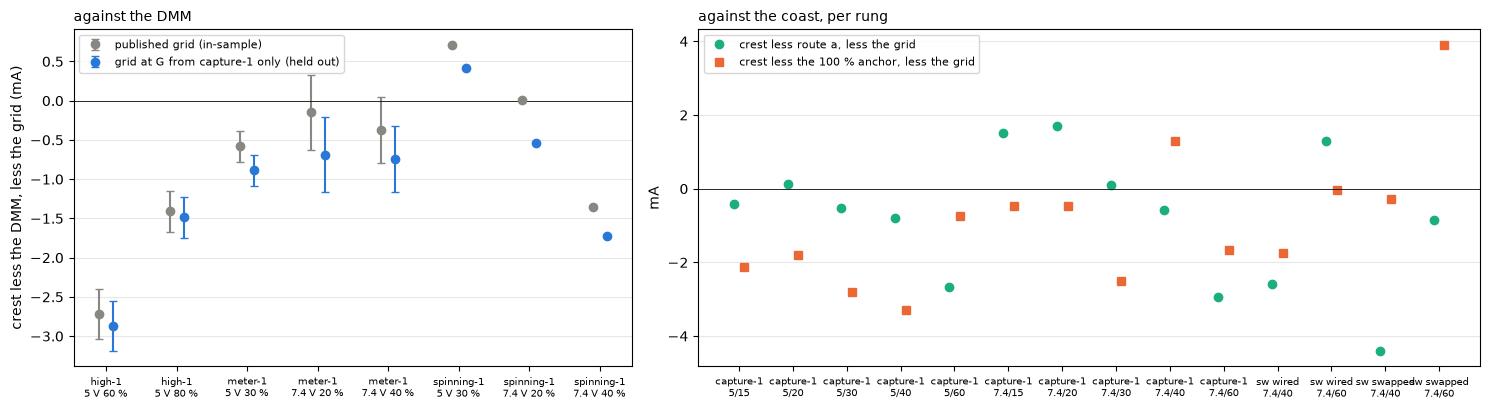

In [17]:
# Delta against the DMM (meter-1, high-1, spinning-1) and against the coast's two truths (route a and the anchor)
M = CT[CT["run"].isin(["meter-1", "high-1"]) & (CT["duty"] < 100)].copy()
M["gap"] = M["i_board_ma"] - M["meter_ma"]                              # crest less the DMM
rows = []
for (run, lv, du), g in M.groupby(["run", "level", "duty"]):
    rows.append(dict(run=run, level=lv, duty=du, n=len(g), gap=g["gap"].mean(), se=g["gap"].std() / np.sqrt(len(g)),
                     grid_pub=cp.grid_lookup(GR, "meter", lv, du, "pub"), grid_held=cp.grid_lookup(GR, "meter", lv, du, "c1only")))
for _, r in PTS[PTS["run"] == "spinning-1"].iterrows():
    rows.append(dict(run="spinning-1", level=r["level"], duty=r["duty"], n=6, gap=r["gap"], se=np.nan,
                     grid_pub=cp.grid_lookup(GR, "meter", r["level"], r["duty"], "pub"), grid_held=cp.grid_lookup(GR, "meter", r["level"], r["duty"], "c1only")))
DM = pd.DataFrame(rows)
DM["less_pub"], DM["less_held"] = DM["gap"] - DM["grid_pub"], DM["gap"] - DM["grid_held"]
print(DM.round(2).to_string(index=False))
for c, lab in (("less_pub", "in-sample, the published grid"), ("less_held", "held out, the grid at G from capture-1 only")):
    print(f"  {lab}: mean {DM[c].mean():+.2f} mA, rms {cp.rms(DM[c]):.2f} mA, max |.| {DM[c].abs().max():.2f}")
h100 = CT[(CT["run"] == "high-1") & (CT["duty"] == 100)]
D100 = (h100["i_board_ma"] - h100["meter_ma"]).agg(["mean", "std", "size"])
print(f"  high-1 at 100 %, crest less the DMM: {D100['mean']:+.2f} mA, sd {D100['std']:.2f}, {int(D100['size'])} spins")
an_c = {x_: CALL[x_].mean() for x_ in idn.ANCHOR_READS}                 # c over all six speed-torque cuts, by each coast read
rows = []
for run in ("capture-1", "swapped-wired", "swapped-swapped"):
    T = TB[run][cp.tach_gate(TB[run])[0]].copy()
    A_ = idn.anchor_delta(T, an_c, SL, run)                             # the anchor, c from all six cuts
    A_["route_a"] = DG["c_scale"] * A_["drag_pin_ma"]                   # the coast's pinned drag scaled to the meter runs
    for (lv, du), g in A_.groupby(["level", "duty"]):
        grid = cp.grid_lookup(GR, "no meter", lv, du)
        rows.append(dict(run=run, level=lv, duty=du, n=len(g), rev_s=g["spin_rev_s"].mean(), route_a=(g["i_crest_200"] - g["route_a"]).mean() - grid,
                         anchor=g["delta_anchor"].mean() - grid))
CO_T = pd.DataFrame(rows)
print(CO_T.round(2).to_string(index=False))
for run, g in CO_T.groupby("run", sort=False):
    print(f"  {run:16s} less the grid: route a mean {g['route_a'].mean():+.2f} mA, rms {cp.rms(g['route_a']):.2f}; "
          f"the anchor mean {g['anchor'].mean():+.2f}, rms {cp.rms(g['anchor']):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw=dict(width_ratios=[1, 1.4]))
a = ax[0]
xl = [f"{r.run}\n{r.level:g} V {int(r.duty)} %" for r in DM.itertuples()]
a.errorbar(np.arange(len(DM)) - 0.1, DM["less_pub"], yerr=2 * DM["se"].fillna(0), fmt="o", color=MUTED, capsize=3, label="published grid (in-sample)")
a.errorbar(np.arange(len(DM)) + 0.1, DM["less_held"], yerr=2 * DM["se"].fillna(0), fmt="o", color=BLUE, capsize=3, label="grid at G from capture-1 only (held out)")
a.axhline(0, color=INK, lw=0.6); a.grid(alpha=0.3, axis="y"); a.set_xticks(range(len(DM)), xl, fontsize=7)
a.set_ylabel("crest less the DMM, less the grid (mA)"); a.legend(fontsize=8); a.set_title("against the DMM", loc="left", fontsize=10)
a = ax[1]
xl = [f"{r.run.replace('swapped-', 'sw ')}\n{r.level:g}/{int(r.duty)}" for r in CO_T.itertuples()]
a.plot(np.arange(len(CO_T)) - 0.1, CO_T["route_a"], "o", color=GREEN, label="crest less route a, less the grid")
a.plot(np.arange(len(CO_T)) + 0.1, CO_T["anchor"], "s", color=ORANGE, label="crest less the 100 % anchor, less the grid")
a.axhline(0, color=INK, lw=0.6); a.grid(alpha=0.3, axis="y"); a.set_xticks(range(len(CO_T)), xl, fontsize=7)
a.set_ylabel("mA"); a.legend(fontsize=8); a.set_title("against the coast, per rung", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

On the left, the crest less the DMM less the meter grid per point, gray the published grid and blue the grid at the $G$ fitted on capture-1 alone. On the right, per rung, crest less each coast truth less the no-meter grid. The thing to see is that the points lie within about 3 mA of zero, two swapped-1 cells at about 4, and that the meter points at 60 and 80 % lie lowest.

Against the DMM the grid predicts the reading term to 1.23 mA rms in-sample and 1.40 mA held out, means -0.73 and -1.07 mA, with the largest miss 2.87 mA at high-1 60 %. It runs 1.4 to 2.9 mA high at 60 and 80 %, the pattern motor-model reports. At 100 % the crest reads -0.13 mA (sd 0.49) under the DMM, so $\Delta$ = 0 there holds. So the grid predicts the DMM-measured term held out to 1.4 mA rms, high confidence. The meter's loop moved from 8.87 to 9.50 ohm after the grid ran, which motor-model sizes at +0.04 to +0.22 mA, inside these residuals.

Against the coast, route a reads capture-1 at -0.45 mA mean and 1.49 mA rms, which is in-sample since $G$ was fitted to it, and swapped-1 at -0.65 mA (2.05 rms) wired and -2.62 mA (3.17 rms) swapped, held out. The anchor reads capture-1 at -1.46 mA (1.95 rms), swapped-1 wired at -0.89 (1.23) and swapped at +1.81 (2.77). swapped-1's swapped 40 % cell reads -4.41 mA by route a and -0.29 by the anchor on the same spins, so that cell depends on the coast read and is not a finding. The anchor's 5 V rungs under 220 rev/s read 1.8 to 3.3 mA under the grid, the pinned read's $c$ about 4 % over the DMM acting on 50 to 70 mA, as identification found. At 2.5 mA, $\Delta$'s error is 11 mV of $R\,i$, 1.5 rev/s, which is 1 % at 150 rev/s.

### G left one run out

$G$ is the spinning loss behind the whole grid. Each half of motor-model's 18 points predicts the other.

capture-1, predicted by the meter-only G: mean +0.06 mA, rms 1.49 mA, max |.| 2.46, rms z 1.00, n 10
the meter points, predicted by the capture-1-only G: mean -0.87 mA, rms 1.24 mA, max |.| 2.63, rms z 1.47, n 8
       run  level  duty   gap  sig  pred_all  held  resid_held  z_held
 capture-1    5.0    15 18.56 1.04     18.88 18.56       -0.00   -0.00
 capture-1    5.0    20 19.48 1.07     19.21 18.91        0.57    0.53
 capture-1    5.0    30 18.82 1.30     19.14 18.88       -0.06   -0.05
 capture-1    5.0    40 17.57 1.43     18.11 17.90       -0.33   -0.23
 capture-1    5.0    60 11.30 1.96     13.75 13.61       -2.31   -1.17
 capture-1    7.4    15 29.84 1.10     28.22 27.75        2.09    1.91
 capture-1    7.4    20 30.72 1.34     28.82 28.38        2.34    1.75
 capture-1    7.4    30 29.22 1.40     28.85 28.47        0.75    0.54
 capture-1    7.4    40 27.07 2.85     27.35 27.03        0.04    0.01
 capture-1    7.4    60 17.98 2.18     20.65 20.44       -2.46   -1.13
    hig

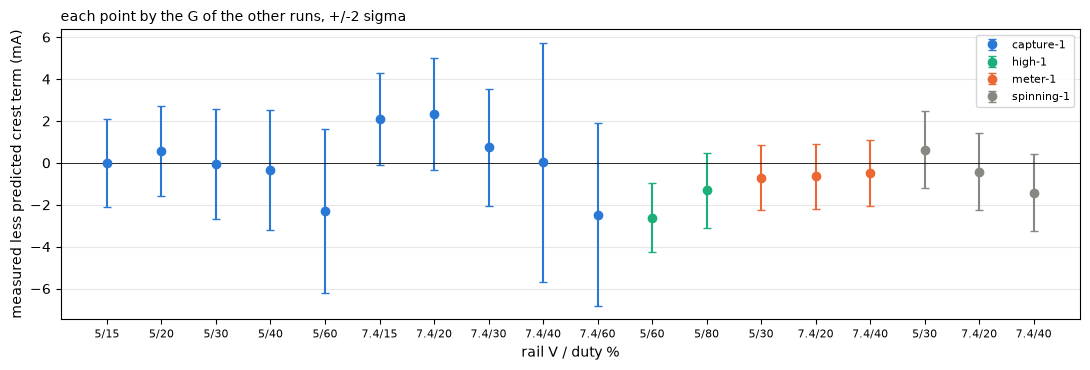

In [18]:
# G left one run out: each point predicted by the G fitted on the other runs
for lab, sel in (("capture-1, predicted by the meter-only G", PTS["run"] == "capture-1"), ("the meter points, predicted by the capture-1-only G", PTS["run"] != "capture-1")):
    r = PTS["resid_held"][sel]
    print(f"{lab}: mean {r.mean():+.2f} mA, rms {cp.rms(r):.2f} mA, max |.| {r.abs().max():.2f}, rms z {cp.rms(PTS['z_held'][sel]):.2f}, n {int(sel.sum())}")
print(PTS[["run", "level", "duty", "gap", "sig", "pred_all", "held", "resid_held", "z_held"]].round(2).to_string(index=False))
nmg = GR[GR["loop"] == "no meter"]
print(f"the no-meter grid at the meter-only G less the published grid: {nmg['meteronly'].sub(nmg['pub']).min():+.2f} to {nmg['meteronly'].sub(nmg['pub']).max():+.2f} mA")
# what the held-out G does to the speed: capture-1, both, power law, the same V_b folds with Delta at the published G
parts = {"held": [], "pub": []}
for rep in range(3):
    te = C1[C1["repeat"] == rep]
    parts["held"].append(cp.score_spins(te, FITS[f"cv{rep}"], FT_HELD, "capture-1"))
    parts["pub"].append(cp.score_spins(te, FITS[f"cv{rep}"], FT_PUB, "capture-1"))
GH = cp.score_table(pd.concat(parts["held"]), ["band"]).set_index("band")["both_revs"] - cp.score_table(pd.concat(parts["pub"]), ["band"]).set_index("band")["both_revs"]
print("held-out G less published G, capture-1 both, rev/s by band: " + ", ".join(f"{b} {x:+.2f}" for b, x in GH.items()))

fig, ax = plt.subplots(figsize=(11, 3.8))
col = {"capture-1": BLUE, "meter-1": ORANGE, "high-1": GREEN, "spinning-1": MUTED}
for run, g in PTS.groupby("run"):
    ax.errorbar(g.index, g["resid_held"], yerr=2 * g["sig"], fmt="o", color=col[run], capsize=3, label=run)
ax.axhline(0, color=INK, lw=0.6); ax.grid(alpha=0.3, axis="y")
ax.set_xticks(PTS.index, [f"{r.level:g}/{int(r.duty)}" for r in PTS.itertuples()], fontsize=8)
ax.set_xlabel("rail V / duty %"); ax.set_ylabel("measured less predicted crest term (mA)")
ax.set_title("each point by the G of the other runs, +/-2 sigma", loc="left", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Each point's measured crest term less the one predicted by the other runs' $G$, with $\pm$2 sigma. The thing to see is that the points straddle zero except at 60 %, where every run reads low.

capture-1 alone gives $G$ = 3.454 $\pm$ 0.100 mS and the meter runs alone 3.270 $\pm$ 0.117 mS, 1.2 sigma apart, which is not a finding. The meter-only $G$ predicts capture-1's points at +0.06 mA mean and 1.49 mA rms (rms z 1.00), and the capture-1-only $G$ predicts the meter points at -0.87 mA and 1.24 mA (rms z 1.47). The model is flat within $\pm$1 mA from 15 to 40 % at 5 V. It runs +2.1 and +2.3 mA at 7.4 V 15 and 20 % (z 1.9 and 1.75) and -2.3 to -2.6 mA at 60 % on every run, high-1 at z -3.2. The 60 % low is the one pattern over 2 sigma. In speed the held-out $G$ against the published one moves capture-1's "both" error by -0.10 to -0.25 rev/s per band, negligible, high confidence. The line in $G$ reproduces the published grid to 0.29 mA (no meter) and a direct run at $G_\mathrm{spin}$ to 0.25 mA.

### A second truth, E0 over Ke

The coast's EMF at the cut over $K_e$ is a speed truth of its own, independent of the ripple count.

In [19]:
# the second truth: the coast's EMF at the cut over Ke, against the ripple tach
E0 = {}
for run in ("capture-1", "swapped-wired", "swapped-swapped", "speed-torque"):
    T = TB[run]
    okr, _ = cp.tach_gate(T)
    d = (T["e_cut"] / cp.KE_REV / T["spin_rev_s"] - 1)[okr] * 100
    E0[run] = dict(n=int(okr.sum()), mean=d.mean(), sd=d.std(), se=d.std() / np.sqrt(okr.sum()))
    print(f"  {run:16s} E0/Ke less the tach: n {E0[run]['n']}, {E0[run]['mean']:+.2f} %, sd {E0[run]['sd']:.2f}, se {E0[run]['se']:.2f}")
g = S_C1[S_C1["form"] == "power"]
E0_SCORE = {v: ((g[f"w_{v}"] - g["truth_e0"]) / g["truth_e0"] * 100).agg(["mean", lambda x: cp.rms(x)]).to_numpy() for v in cp.VARIANTS}
print("capture-1 held out against E0/Ke: " + ", ".join(f"{v} {m:+.2f} / {r:.2f} %" for v, (m, r) in E0_SCORE.items()))

  capture-1        E0/Ke less the tach: n 60, -0.20 %, sd 0.56, se 0.07
  swapped-wired    E0/Ke less the tach: n 9, -0.45 %, sd 0.36, se 0.12
  swapped-swapped  E0/Ke less the tach: n 9, -0.60 %, sd 0.37, se 0.12
  speed-torque     E0/Ke less the tach: n 4, -0.12 %, sd 0.83, se 0.41
capture-1 held out against E0/Ke: none -8.38 / 11.76 %, delta +0.72 / 3.38 %, vb -9.65 / 11.81 %, both -0.73 / 1.68 %


$E_0/K_e$ reads 0.12 to 0.60 % under the ripple tach, -0.20 % on capture-1 (se 0.07), -0.45 and -0.60 % on swapped-1 (se 0.12) and -0.12 % on speed-torque's four gated cuts (se 0.41). That is the speed trend of $K_e$ that route 3 of identification reads, -0.22 % per 100 rev/s, and the reason $V_b$ is fitted against the tach: fitted against $E_0$ the estimator would inherit it as a bias of about -0.9 % at 450 to 600 rev/s. Against $E_0/K_e$ instead of the tach, capture-1's held-out "both" reads -0.73 % mean and 1.68 % rms with the power law, against -0.93 and 1.74 % on the tach. The two truths agree to within $K_e$'s $\pm$0.51 % bounds on every capture but swapped-1's swapped block, which sits 0.09 points outside them. High confidence that the headline does not depend on which truth is used.


### R moved 2 %

The locked $R$ is read at about 0.78 A with the rotor still. The estimator uses it at every speed and current.

r_factor                   0.98          1.00          1.02
capture   band                                             
capture-1 0-100    -0.92 (1.11)  -1.72 (1.86)  -2.52 (2.64)
          100-160  -1.27 (2.00)  -1.82 (2.44)  -2.38 (2.91)
          160-250  +0.30 (0.55)  -0.08 (0.45)  -0.46 (0.63)
          250-350  +0.07 (0.60)  -0.20 (0.63)  -0.47 (0.76)
          450-600  +0.21 (0.68)  +0.00 (0.64)  -0.20 (0.67)
run-up    160-250  +4.26 (5.19)  +0.59 (3.15)  -3.09 (4.49)
          250-350  +3.76 (3.94)  +1.85 (2.11)  -0.07 (1.05)
          350-450  +2.62 (3.12)  +1.70 (2.47)  +0.79 (2.04)
          450-600  +2.07 (2.81)  +1.73 (2.56)  +1.39 (2.33)
swapped-1 250-350  -1.90 (1.97)  -2.13 (2.20)  -2.37 (2.42)
          450-600  -0.83 (0.85)  -1.01 (1.03)  -1.19 (1.21)


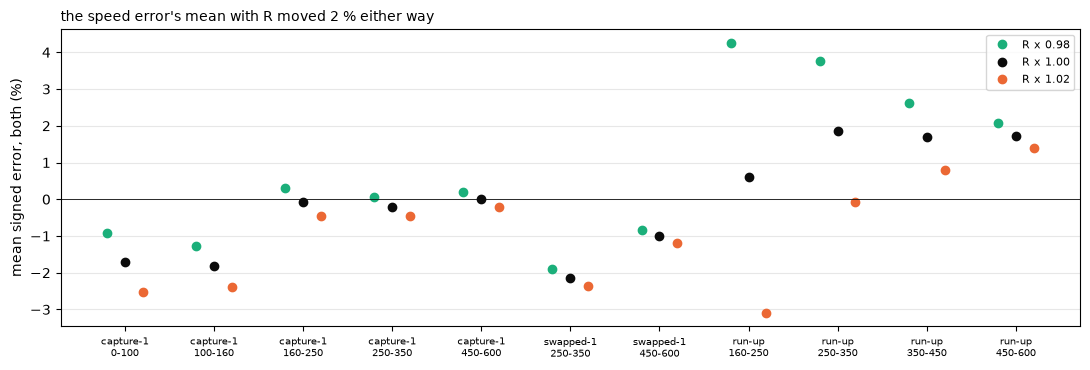

In [20]:
# R at 0.98, 1 and 1.02 of the locked R, both compensations, power law, the held-out designs
RS_ = []
for fac in (0.98, 1.0, 1.02):
    r = cp.R_LOCKED * fac
    parts = [cp.score_spins(C1[C1["repeat"] == rep], FITS_S[f"cv{rep}"], FT_HELD, "capture-1", r=r, form="table") for rep in range(3)]
    for cap, S in (("capture-1", pd.concat(parts)),
                   ("swapped-1", pd.concat([cp.score_spins(SW[b], FIT_S, FT_PUB, "sw", r=r, form="table") for b in SW])),
                   ("run-up", cp.score_windows(RU, FIT_S, "table", r=r))):
        for _, x in cp.score_table(S, ["band"], variants=("both",)).iterrows():
            RS_.append(dict(r_factor=fac, capture=cap, band=x["band"], n=x["n"], mean_pct=x["both_pct"], rms_pct=x["both_rms_pct"]))
RSN = pd.DataFrame(RS_)
print(RSN.assign(cell=[f"{a:+.2f} ({b:.2f})" for a, b in zip(RSN["mean_pct"], RSN["rms_pct"])]).pivot(index=["capture", "band"], columns="r_factor", values="cell").to_string())

fig, ax = plt.subplots(figsize=(11, 3.8))
keys = RSN[RSN["r_factor"] == 1.0][["capture", "band"]].apply(tuple, axis=1).tolist()
for j, (fac, col) in enumerate(((0.98, GREEN), (1.0, INK), (1.02, ORANGE))):
    h = RSN[RSN["r_factor"] == fac].set_index(["capture", "band"]).loc[keys]
    ax.plot(np.arange(len(keys)) + (j - 1) * 0.2, h["mean_pct"], "o", color=col, ms=6, label=f"R x {fac:.2f}")
ax.axhline(0, color=INK, lw=0.6); ax.grid(alpha=0.3, axis="y")
ax.set_xticks(range(len(keys)), [f"{c}\n{b}" for c, b in keys], fontsize=7); ax.set_ylabel("mean signed error, both (%)")
ax.set_title("the speed error's mean with R moved 2 % either way", loc="left", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The mean signed error, both compensations, the speed table, at 0.98, 1 and 1.02 of the locked $R$. The thing to see is that the free shaft and the loaded run-ups want $R$ moved opposite ways.

The free shaft at low speed prefers $R$ about 2 % under the locked value. At 0 to 100 rev/s capture-1 reads -0.92 % at 0.98 against -1.72 % at 1, and motor-model's running $R$ under 160 rev/s is 4.316 ohm, 3.1 % under. The loaded run-ups prefer it about 2 % over, 250 to 350 rev/s reading -0.07 % at 1.02 against +1.85 % at 1, near motor-model's incremental 4.579 ohm. One $R$ serves both only to about 1 % of speed, moderate confidence. swapped-1's -2.1 and -1.0 % do not move toward zero either way, since its bias is $V_b$'s.


### The error budget

Each known term's 1 sigma as motor rev/s, by band, against the observed held-out rms. $\Delta$ is 1.39 mA, the held-out residual rms over the 18 points. $R$ is $\pm$2 %. $K_e$ is half of bemf-coast's bounds, $\pm$0.51 %. The share construction's edge term is $\pm$5 mV, motor-model's band. $V_b$ is the spread of the three fold fits at the band's speeds and dropouts. Noise is the 200 ms means' own standard error, or for the run-ups the one-turn windows' 98 mV scatter. The observed figures are capture-1 by repeat and the speed-torque run-ups, both held out.


Delta 1.39 mA, R +/-2 %, Ke +/-0.51 %, share edge +/-5 mV, window scatter 98 mV; rev/s:
   form           band    n  rev_s   i_ma  delta   vb    R   Ke  share  noise  known  obs_mean  obs_rms  unexplained  obs_rms_pct  horn_deg_s
  power          0-100   12  79.13  50.96   0.84 0.02 0.62 0.41   0.68   0.09   1.31     -1.32     1.36         0.35         1.72        1.59
  power        100-160   18 135.91  61.77   0.84 0.08 0.75 0.70   0.68   0.08   1.50     -2.45     2.98         2.58         2.19        3.48
  power        160-250   12 226.98  71.02   0.84 0.27 0.86 1.17   0.68   0.08   1.83     -0.31     1.25         0.00         0.55        1.46
  power        250-350   12 328.66  82.42   0.84 0.62 1.00 1.69   0.68   0.14   2.33      1.43     2.80         1.55         0.85        3.27
  power        450-600    6 492.92  94.10   0.84 1.58 1.14 2.53   0.68   0.35   3.39     -1.78     5.33         4.11         1.08        6.23
  power run-up 160-250   28 219.57 671.52   0.00 0.22 8.15 1

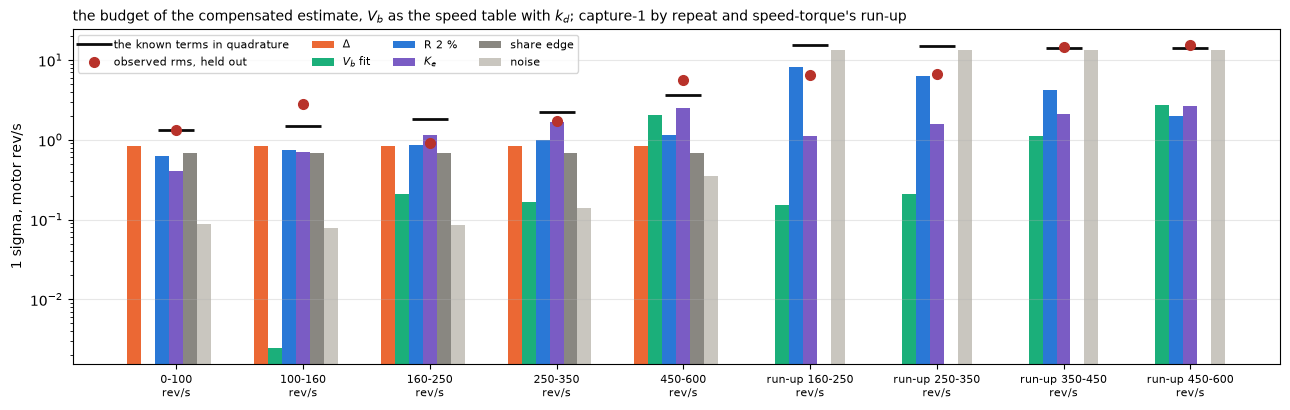

In [21]:
# the error budget, both compensations, by band: each term's 1 sigma in motor rev/s against the observed held-out rms
SIG_DELTA = cp.rms(PTS["resid_held"])                                   # Delta, the held-out residual rms over the 18 points, mA
SIG_R = 0.02                                                            # R, +/- 2 %
KE_HALF = (cp.KE_HI - cp.KE_LO) / 2 / cp.KE                             # Ke, half of bemf-coast's bounds
SIG_SHARE = bd.DELTA_SYS_MV                                             # the share construction's edge term, motor-model's band, mV
WIN_NOISE = WS / cp.KE_REV                                              # one turn window's own scatter as speed
rows = []
for form in FORMS:
    C_ = S_C1[S_C1["form"] == form]
    W_ = S_ST[(S_ST["form"] == form) & (S_ST["part"] == "run-up")]
    for band, S in list(C_.groupby("band")) + [("run-up " + b, g) for b, g in W_.groupby("band")]:
        st = band.startswith("run-up")
        w = S["truth"].mean()
        i = S["i"].mean() if st else S["i_hat_d"].mean() * 1e-3
        mech = (S["dir"] * cp.MECH["speed-torque"]).to_numpy() if st else S["mech"].to_numpy()
        dr = (S["dropouts_per_s"] if st else S["dropouts"]).to_numpy()
        vb_cv = np.array([cp.vb_total(form_fit(form, f"cv{k}")[0], mech, S["truth"].to_numpy(), dr, form_fit(form)[1]).mean() for k in range(3)])
        t = dict(delta=0.0 if st else cp.R_LOCKED * SIG_DELTA * 1e-3 / cp.KE_REV, vb=vb_cv.std(ddof=1) * 1e-3 / cp.KE_REV,
                 R=SIG_R * cp.R_LOCKED * i / cp.KE_REV, Ke=KE_HALF * w, share=0.0 if st else SIG_SHARE * 1e-3 / cp.KE_REV,
                 noise=WIN_NOISE if st else cp.rms(np.hypot(S["share"] * S["v_on_se_200"], cp.R_LOCKED * S["i_crest_se_200"] * 1e-3)) / cp.KE_REV)
        known = cp.quadrature(*t.values())
        e = S["w_both"] - S["truth"]
        rows.append(dict(form=form, band=band, n=len(S), rev_s=w, i_ma=i * 1e3, **t, known=known, obs_mean=e.mean(), obs_rms=cp.rms(e),
                         unexplained=cp.unexplained(cp.rms(e), known), obs_rms_pct=cp.rms(e) / w * 100, horn_deg_s=cp.rms(e) * 360 / cp.GEAR))
BUD = pd.DataFrame(rows)
print(f"Delta {SIG_DELTA:.2f} mA, R +/-{SIG_R * 100:.0f} %, Ke +/-{KE_HALF * 100:.2f} %, share edge +/-{SIG_SHARE:.0f} mV, window scatter {WS * 1e3:.0f} mV; rev/s:")
print(BUD.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 4.2))
B_ = BUD[BUD["form"] == "table+d"].reset_index(drop=True)
terms = [("delta", ORANGE, r"$\Delta$"), ("vb", GREEN, r"$V_b$ fit"), ("R", BLUE, "R 2 %"), ("Ke", "#7a5cc4", r"$K_e$"), ("share", MUTED, "share edge"), ("noise", "#c9c6bf", "noise")]
for j, (k, col, lab) in enumerate(terms):
    ax.bar(np.arange(len(B_)) + (j - 3) * 0.11, B_[k], 0.11, color=col, label=lab)
ax.plot(np.arange(len(B_)), B_["known"], "_", color=INK, ms=26, mew=2, label="the known terms in quadrature")
ax.plot(np.arange(len(B_)), B_["obs_rms"], "o", color="#b8322a", ms=7, label="observed rms, held out")
ax.set_yscale("log"); ax.grid(alpha=0.3, axis="y")
ax.set_xticks(range(len(B_)), [f"{b}\nrev/s" for b in B_["band"]], fontsize=8); ax.set_ylabel("1 sigma, motor rev/s")
ax.set_title(r"the budget of the compensated estimate, $V_b$ as the speed table with $k_d$; capture-1 by repeat and speed-torque's run-up", loc="left", fontsize=10)
ax.legend(fontsize=8, ncol=4, loc="upper left"); plt.tight_layout(); plt.show()

Bars are the known terms, the black tick their sum in quadrature and the red dot the observed rms, on a log scale, for the table with $k_d$; the printed table has all three forms. The thing to see is where the red dot sits over the black tick, which is where something the budget does not hold is at work.

- Under 350 rev/s on the free shaft the known terms add to 1.3 to 2.3 rev/s and the observed rms is 0.9 to 2.8 rev/s, 1.0 to 3.3 deg/s at the horn. $\Delta$, $R$, $K_e$ and the share edge are each 0.4 to 1.7 rev/s, and no single term dominates. Over 250 rev/s $K_e$ leads.
- The one unexplained piece under 350 rev/s is 2.4 rev/s at 100 to 160 rev/s, the rail term at 7.4 V.
- At 490 rev/s the speed table's 3.2 rev/s observed sits inside its 3.3 known; the power law leaves 4.1 rev/s unexplained, its misfit at the top rungs, and the table with $k_d$ 4.4, the spread of $k_d$ and its tables between the folds at the one rung that sets them.
- On the run-ups, at 160 to 670 mA in the band means, $R$'s 2 % is the largest systematic term, 2 to 8 rev/s, and the windows' own scatter of 13 rev/s owns most of the rms; with $k_d$ the bands over 350 rev/s leave 4 to 7 rev/s unexplained, the dropout relation past the rate it was read at.
- Not in this in-sitting budget is $V_b$'s move between sittings, 3 to 16 rev/s at 330 to 490 rev/s on swapped-1.


## Results

Every finding with its confidence.

- **Both compensations together** take the speed error from 4.6 to 11.8 % rms uncompensated to 1.6 to 2.5 % rms held out on every capture with $V_b$ as the speed table, 1.6 to 3.5 % with $k_d$ and 1.6 to 2.8 % with the power law. On the free shaft from 160 rev/s up it is under 0.7 % with the table. High confidence.
- **Either compensation alone can make the estimate worse.** $\Delta$ and $V_b$ pull opposite ways, so on capture-1's 250 to 350 rev/s band $\Delta$ alone moves -1.0 % to +2.9 % and $V_b$ alone to -3.6 %. High confidence.
- **The constants identified board-only cost** +0.63 points of rms on capture-1, +0.13 on the run-ups and nothing elsewhere, the median of 36 passes. Almost all of it is $\Delta$ through the anchor, under 160 rev/s. High confidence on where it comes from, moderate on its size, from three anchor passes.
- **Three rungs hold $V_b$.** 7.4 V at 30, 40 and 60 % both ways, six spins of one repeat over 50 ms windows, holds the 0.2 point rule on every held-out set with margins of 0.05 points or better. Moderate confidence.
- **The direction split of $V_b$ is the dropout rate.** With $k_d$ out, the residual split between the directions at the three rungs that drop out is +6, 0 and +1 mV against +30, -66 and +7 under the power law; at swapped-1's 40 % cell the split is 2.6 mV of speed part and 37.6 mV of dropouts. High confidence within capture-1.
- **The dropout form trades.** It wins on capture-1 from 160 to 350 rev/s (0.39 and 0.52 % rms against 0.45 and 0.63) and on swapped-1's swapped block (1.60 against 2.13 %), and loses on the run-ups (3.04 against 2.54 %) and the settled windows (3.49 against 2.28 %), where the rate reaches 960 a second against the 480 the free spins fitted it on and $k_d$ over-predicts by about 120 mV. Moderate confidence that the relation bends there, from one direction of one capture.
- **$f(D)$ per volt does not depend on the rail** to 0.3 mA on 3.7 to 7.4 V, for the model's grid. High confidence.
- **The power law misfits capture-1's top rungs** by 3 to 6 sigma per rung, and parts from the table by 55 to 242 mV past 480 rev/s in mech +1. High confidence on the misfit, moderate that the table is the better form.
- **$V_b$ follows the mechanical rotation**, +55 $\pm$ 3 mV measured against +58 predicted by the mechanical mapping and -68 by the board's at 40 %. High confidence on the sign at that duty, the only one where both wired directions survive the gate, and moderate as a rule. Under the dropout form the direction the table must know is the one that drops out, which the board counts.
- **$V_b$ dropped by a tenth to all of itself between 10-28 and 10-29**, which is swapped-1's -1.3 to -2.0 % bias; the dropout rate halved with it. Moderate confidence. Two sittings, with a broken lead replaced between them.
- **$X$ carries a rail term**, about 20 to 25 mV lower at 7.4 V than at 5 V at the same speed from 65 to 335 rev/s, 17 to 40 sigma per rung under 160 rev/s, which no form of $V_b$ holds and which costs 1.7 to 4.0 % of speed at the 7.4 V low rungs. The grid's miss covers about half of it at low speed. High confidence that it is there, mechanism not tested.
- **The grid predicts the DMM's reading term held out to 1.4 mA rms**, high confidence. The coast's truths agree to 1.2 to 3.2 mA rms by rung.
- **$G$ left one run out** moves 1.2 sigma and the speed by under 0.25 rev/s. High confidence that it does not matter here.
- **$E_0/K_e$ reads 0.1 to 0.6 % under the tach**, the speed trend of $K_e$, which is why $V_b$ is fitted against the tach; fitted against $E_0$ the top band would read about 0.9 % low. High confidence.
- **$R(T)$ by the board NTC moves nothing** past 0.2 points, because the winding sat near room temperature. High confidence for these data, untested on a warm winding.
- **$R \pm 2$ %** moves the low-speed free shaft and the loaded run-ups in opposite directions, so one $R$ serves both only to about 1 %. Moderate confidence.
- **The error budget** under 350 rev/s is 1.3 to 2.3 rev/s of known terms against 0.9 to 2.8 observed, with no single term dominating. The rail term at 100 to 160 rev/s and, at 490 rev/s, the power law's form and the dropout relation's spread are the unexplained parts.

The result file carries `headline` (by $V_b$ form, capture and band, each variant's mean and rms in % and rev/s, and `in_sample_published`), `identified` (by pass tag A, B, C, B+R, B+Ke, B+Delta, B+L, A+d and C+d, capture and band, the median pass with the rms range), `r_of_t`, `vb_subsets`, `delta_f_ma_per_v`, `g_spin_ms`, `v_b` (the fits by direction, $k_d$ by fit, the dropout threshold, capture-1's tables by knot with and without $k_d$, and the low-speed rung means), `direction_mapping`, `v_b_between_sittings`, `delta_vs_dmm_ma`, `delta_vs_coast_ma`, `e0_truth_pct`, `r_sensitivity_pct` and `budget_rev_s`.


In [22]:
q = results.quantity

def scores_dict(df, keys=("none", "delta", "vb", "both")):
    # one capture's rows by band: n, the tach speed, and each variant's mean and rms in % and rev/s
    out = {}
    for _, r in df.iterrows():
        d = {"n": q(r["n"], unit="count"), "tach_rev_s": q(r["rev_s"], unit="rev/s")}
        for v in keys:
            d[v] = {"mean_pct": q(r[f"{v}_pct"], unit="%"), "rms_pct": q(r[f"{v}_rms_pct"], unit="%"),
                    "mean_rev_s": q(r[f"{v}_revs"], unit="rev/s"), "rms_rev_s": q(r[f"{v}_rms_revs"], unit="rev/s")}
        out[r["band"]] = d
    return out

headline = {form: {cap: scores_dict(HL[(HL["capture"] == cap) & (HL["form"] == form)]) for cap in HL[HL["held"] == "held out"]["capture"].unique()}
            for form in FORMS}
headline["in_sample_published"] = scores_dict(HL[HL["held"] == "in-sample"])
ident = {}
for t, s in SUM.items():
    ident[t] = {cap: {r["band"]: {"mean_pct": q(r["mean_pct"], unit="%"), "rms_pct": q(r["rms_pct"], r["rms_lo"], r["rms_hi"], "%"),
                                  "passes": q(r["passes"], unit="count")} for _, r in g.iterrows()} for cap, g in s.groupby("capture")}
r_of_t = {f"{t} {m}": {c: q(g.set_index("capture").loc[c, "rms_pct"], unit="%") for c in cp.CAPS}
          for (t, m), g in RTS[RTS["band"] == "all"].groupby(["tag", "model"])}
subsets = {f"{pre} ms": {lab: {"holds": bool(HOLDS.loc[(pre, lab)]), **{c: q(*VSM[(VSM["pre"] == pre) & (VSM["subset"] == lab) & (VSM["capture"] == c)][["median", "min", "max"]].iloc[0], "%")
                                                                   for c in cp.CAPS}} for lab in cp.SUBSETS} for pre in (200, 50)}
fd = {f"{d} %": q(FPIV.loc[d, "mean"], FPIV.loc[d, list(cp.RAILS)].min(), FPIV.loc[d, list(cp.RAILS)].max(), "mA/V") for d in FPIV.index}
vb_fits = {lab: {f"{m:+d}": {"mv_at_300_rev_s": q(f[m]["power"][0], unit="mV"), "exponent": q(f[m]["power"][1], unit="")} for m in (1, -1)}
           for lab, f in FITS_S.items()}
vb_table = {f"{m:+d}": {f"{k:.0f} rev/s": q(v, unit="mV") for k, v in zip(cp.VB_KNOTS, FIT_S[m]["table"])} for m in (1, -1)}
vb_speed_part = {f"{m:+d}": {f"{k:.0f} rev/s": q(v, unit="mV") for k, v in zip(cp.VB_KNOTS, FIT[m]["table"])} for m in (1, -1)}
vb_kd = {lab: q(f["k_d"], f["k_d"] - f["k_d_se"], f["k_d"] + f["k_d_se"], "mV s") for lab, f in FITS.items()}
budget = {f"{r['form']} {r['band']}": {k: q(r[k], unit="rev/s") for k in ("delta", "vb", "R", "Ke", "share", "noise", "known", "obs_mean", "obs_rms", "unexplained")}
          | {"obs_rms_pct": q(r["obs_rms_pct"], unit="%"), "horn_deg_s": q(r["horn_deg_s"], unit="deg/s")} for _, r in BUD.iterrows()}
NOTES = ("compensation runs the back-EMF speed estimate w = (V_mean - R (i_crest - Delta) - V_b(w, mech dir)) / Ke, solved by fixed point, "
         "through stage 2's mg90-b captures from the board's own signals and grades it against the ripple tach. headline: by V_b form (power, "
         "table), capture and speed band, each variant (none, delta, vb, both) as mean and rms in % of the tach and in rev/s; capture-1 is scored "
         "by the fold that left its repeat out of V_b, with Delta at G fitted on the meter runs only; swapped-1 and speed-torque are scored on "
         "capture-1's V_b and the published grid and were never in a fit; in_sample_published is capture-1 on motor-model's V_b and grid. "
         "identified: the same estimate, V_b as the table, both compensations, per pass tag (A reference constants, B reference R, Ke, Delta "
         "with V_b from one repeat's 7.4 V 30/40/60 % over 50 ms, C every constant identified, B+X one identified constant in B), the median "
         "pass with the rms range over the passes as bounds. r_of_t: all-band rms with R fixed, by the board NTC, and with the self-heat bound. "
         "vb_subsets: identification's V_b subsets scored like B, the median pass with its range, holds if within 0.2 points of A on every set. "
         "delta_f_ma_per_v: the published no-meter grid per volt, the rail mean with the rails' range. g_spin_ms: G by run left out. "
         "v_b: the fits by mechanical direction and capture-1's speed table. direction_mapping, v_b_between_sittings, delta_vs_dmm_ma, "
         "delta_vs_coast_ma, e0_truth_pct, r_sensitivity_pct and budget_rev_s as the notebook states them.")
out = results.write(
    "2-motor", "compensation", cp.PAIR, pair=cp.MOTOR.key, notes=NOTES,
    headline=headline, identified=ident, r_of_t=r_of_t, vb_subsets=subsets,
    delta_f_ma_per_v=fd,
    g_spin_ms={k: q(g * 1e3, (g - se) * 1e3, (g + se) * 1e3, "mS") for k, (g, se, chi2) in GF.items()}
              | {"held_out_resid_rms_ma": q(SIG_DELTA, unit="mA")},
    v_b={"fits": vb_fits, "table_mv": vb_table, "speed_part_with_k_d_mv": vb_speed_part, "k_d_mv_per_dropout_s": vb_kd,
         "dropout_threshold": q(cp.idn.tel.DROPOUT_FRAC, unit=""), "low_speed_rung_means_mv": {f"{r.level:g} V {int(r.duty)} % mech {int(r.mech):+d}": q(r.x, r.x - r.se, r.x + r.se, "mV")
                                                                           for r in LOW.itertuples()}},
    direction_mapping={"wired_40_split_mv": q(SPLIT["measured"], SPLIT["measured"] - SPLIT["se"], SPLIT["measured"] + SPLIT["se"], "mV"),
                       "predicted_mech_mv": q(SPLIT["mech"], unit="mV"), "predicted_board_mv": q(SPLIT["board"], unit="mV"),
                       "wired_40_speed_error_pct": {mp: {f"{k:+d}": q(v, unit="%") for k, v in d.items()} for mp, d in MAP_SPEED.items()},
                       "with_k_d_speed_part_mv": q(SPLIT["speed_part"], unit="mV"), "with_k_d_dropout_part_mv": q(SPLIT["dropout_part"], unit="mV")},
    v_b_between_sittings={f"{r.block} {int(r.duty)} % mech {int(r.mech):+d}": {"measured_mv": q(r.measured_mv, unit="mV"), "power_mv": q(r.power_mv, unit="mV"),
                                                                              "table_mv": q(r.table_mv, unit="mV"), "less_table_rev_s": q(r.less_table_rev_s, unit="rev/s"),
                                                                              "table_d_mv": q(r.table_d_mv, unit="mV"), "less_table_d_rev_s": q(r.less_table_d_rev_s, unit="rev/s")}
                          for r in SIT.itertuples()},
    delta_vs_dmm_ma={"in_sample": q(DM["less_pub"].mean(), unit="mA"), "in_sample_rms": q(cp.rms(DM["less_pub"]), unit="mA"),
                     "held_out": q(DM["less_held"].mean(), unit="mA"), "held_out_rms": q(cp.rms(DM["less_held"]), unit="mA"),
                     "full_duty_crest_less_dmm": q(D100["mean"], D100["mean"] - D100["std"], D100["mean"] + D100["std"], "mA")},
    delta_vs_coast_ma={run: {"route_a": q(g["route_a"].mean(), unit="mA"), "route_a_rms": q(cp.rms(g["route_a"]), unit="mA"),
                             "anchor": q(g["anchor"].mean(), unit="mA"), "anchor_rms": q(cp.rms(g["anchor"]), unit="mA")} for run, g in CO_T.groupby("run")},
    e0_truth_pct={run: q(d["mean"], d["mean"] - d["se"], d["mean"] + d["se"], "%") for run, d in E0.items()},
    r_sensitivity_pct={f"x {fac:.2f}": {f"{r.capture} {r.band}": q(r.mean_pct, unit="%") for r in g.itertuples()} for fac, g in RSN.groupby("r_factor")},
    budget_rev_s=budget,
)
print(out)

stages/2-motor/compensation/results/mg90-b.json


## Limitations

- One motor, mg90-b, so every number is this motor's.
- No load on the shaft. The only current lever at fixed speed is the 100 % run-up, 5 V only, accelerating through 188 to 577 rev/s.
- Two sittings for the free spins, capture-1 and swapped-1 a day apart, and a third day for the meter runs. A motor lead broke and was replaced between the first two.
- No spin at 3.7 V. $f(D)$ there is the model's, and the rail term's dependence on the rail is untested.
- Under 330 rev/s only capture-1 is meter-free, so its low bands are held out by repeat within one sitting.
- Every spin ran 1.5 s, and the identified passes read a 50 ms window cut out of it. A short spin that has run only about 115 ms is not tested.
- The dropout rate is read over 200 or 50 ms on the free spins and over 50 ms around each run-up window; $k_d$ is fitted on rates up to 480 a second and the run-ups reach 960. The threshold's gap is partial on this motor, 35 % of the rows under 0.40 of the window mean sitting within 0.10 to 0.40 of it.
- The meter runs are not speed-scored, since their meter loop in the voltage path was derived with $V_b$.
- The winding stayed near room temperature, so $R(T)$ is untested on a warm winding.
- The identified passes are three repeats and twelve seats, so the anchor's spread is known over three passes, not to a confidence interval.

## Open questions

- What the rail term is. If it is the crest term's split by rail, the same rungs at 3.7 V read it smaller in proportion to the rail, and a meter in series at 7.4 V 15 % reads the grid's miss directly. If it is the tap's edge lag, it scales with the rail at every speed and a sample-timing run at 7.4 V narrows it. If it is in the motor, it stays the same at 3.7 V.
- Why $V_b$ dropped between the sittings, and whether its dropout rate dropped with it for the same reason. A change at the replaced lead's joint predicts a step that stays, and a brush film predicts a drift with use. The same reference rungs at the start and end of several sittings, with no lead work between them, separate the two.
- Whether the dropout relation bends past 500 a second or the 100 % run-ups carry another term. Free spins at 7.4 V 80 and 100 % read the rate between 480 and 960 a second with no load current to confound it.
- Whether the run-up's residual is a running $R$ or a current-dependent $V_b$. A running $R$ predicts a residual proportional to the current at one speed, which a run-up at two rails at the same speeds would read.
- Whether $V_b$ and $\Delta$ read the same from a short spin as from a 1.5 s spin.

identification lists what the next motor's capture must record so every route there runs on it, and the same list closes these questions. The compensation estimator needs nothing beyond it.

## Conclusion

With both compensations the board's own back-EMF estimate reads within 1.6 to 2.5 % rms of the ripple tach on every held-out capture with $V_b$ as the speed table, 1.6 to 3.5 % with the dropout term and 1.6 to 2.8 % with the power law. From 160 rev/s up on the free shaft the floor is 0.4 to 0.7 %, 0.9 to 2.1 rev/s or 1.0 to 2.4 deg/s at the horn, set by $\Delta$, $R$, $K_e$ and the share edge in about equal parts. Under 160 rev/s a rail term costs about 2 % at 7.4 V, and above 450 rev/s $V_b$'s form and its move between sittings cost 1 to 3 %. Uncompensated the same estimate reads 17 to 21 % low at 15 % duty and 8 to 9 % high at 100 %, and either compensation alone can make it worse.

The dropout term explains what the speed tables could not: the split between the two directions of rotation is the dropout rate, which the board counts itself, and a third of the day-to-day change on swapped-1 is in that count. It wins on the free shaft and loses at 100 %, where the rate runs to twice what the free spins fitted it on, so which form the firmware carries waits on the next motor's capture, which records the rate between.

With every constant from the board instead of the bench, the estimate costs 0.6 points of rms on capture-1 and 0.1 or less elsewhere, the median of 36 passes, and that price is almost all $\Delta$ through the anchor under 160 rev/s. Confidence is high on the in-sitting numbers and moderate on the transfer across sittings, because $V_b$ moved by a tenth to all of itself in one day.
